# C2 — RoBERTa: phần của Đức Trí

**Mục tiêu:** hiểu code, trực quan hóa kết quả và dùng làm notebook báo cáo cá nhân.

Bạn phụ trách RoBERTa: dữ liệu/tokenizer → fine-tune → 3 seed → metrics → ngưỡng → lỗi → phần viết C2.
Zero-shot B là phần bàn giao/hỗ trợ Duy. BERT thuộc Khánh; DistilBERT và demo thuộc Huy.

## Notebook có hai phần

1. **Phần đã chạy được ở đây:** code đọc snapshot kết quả thực nghiệm chung, tính lại mean/std, vẽ learning curves,
   so sánh fixed/tuned và ba C, bảng nhãn hiếm, ví dụ lỗi. Output đã lưu trong notebook.
2. **Phần chạy RoBERTa của bạn:** các ô dùng trainer/metrics chung của nhóm. Mặc định tắt training để
   Run All không tải model hoặc train hàng giờ. Bật từng cờ sau khi có repo mới, môi trường và dữ liệu/model.

**Giới hạn:** các bảng benchmark là kết quả đã chạy trên máy nhóm, không phải lượt fine-tune mới trên máy Đức Trí.
Notebook này không chứa weights hoặc scores NPZ đầy đủ. Không tự nhận đóng góp cá nhân chỉ vì có kết quả chung.

**Tác giả phần notebook/giải thích: Đức Trí — [Ductri2006](https://github.com/Ductri2006).**
Trainer/metrics và kết quả thực nghiệm chung được dùng lại từ repo nhóm, giữ nguồn; không đổi tác giả lịch sử các run.

## 1. Môi trường để đọc bảng/biểu đồ

Mở bằng VS Code/Jupyter, chọn kernel Python có `numpy`, `pandas`, `matplotlib`.
Nếu thiếu, chạy `%pip install numpy pandas matplotlib` trong kernel đó. Không cần GPU để đọc phần báo cáo.
Snapshot nhúng bên dưới giúp notebook chạy độc lập, không cần tải CSV hoặc có thư mục evidence.

In [1]:
from pathlib import Path
import json, sys, importlib.util, subprocess, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 14)
pd.set_option('display.precision', 4)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
print('Python:', sys.version.split()[0])
print('Chế độ mặc định: đọc/đối chiếu hồ sơ nhóm; chưa train lại RoBERTa.')

Python: 3.13.1
Chế độ mặc định: đọc/đối chiếu hồ sơ nhóm; chưa train lại RoBERTa.


In [2]:
SNAPSHOT = json.loads('{"commit": "3c44309ec287d3a2926acdd67a9b6a18da11a4d2", "repository": "trangkhanh-ai/goemotions-multilabel-classification", "all_runs": [{"system": "C_bert", "seed": "42.0", "split": "validation", "threshold_mode": "fixed", "macro_f1": "0.46414774478497617", "micro_f1": "0.5759768451519537", "macro_precision": "0.521075016554571", "macro_recall": "0.42836015730364396", "micro_precision": "0.6303335196571641", "micro_recall": "0.5302507836990595", "hamming_loss": "0.03278526670528145", "n_samples": "5426"}, {"system": "C_bert", "seed": "42.0", "split": "validation", "threshold_mode": "global", "macro_f1": "0.4927457926955244", "micro_f1": "0.5794634345635299", "macro_precision": "0.4507042438284747", "macro_recall": "0.5612025743244068", "micro_precision": "0.512280279316157", "micro_recall": "0.6669278996865203", "hamming_loss": "0.04065083460586594", "n_samples": "5426"}, {"system": "C_bert", "seed": "42.0", "split": "validation", "threshold_mode": "tuned", "macro_f1": "0.5266106483648556", "micro_f1": "0.5979041056560437", "macro_precision": "0.5304375838669704", "macro_recall": "0.5473210338558041", "micro_precision": "0.551509533898305", "micro_recall": "0.6528213166144201", "hamming_loss": "0.036872729187509876", "n_samples": "5426"}, {"system": "C_bert", "seed": "42.0", "split": "test", "threshold_mode": "fixed", "macro_f1": "0.4697007290666148", "micro_f1": "0.5832118665866415", "macro_precision": "0.5284576589287656", "macro_recall": "0.43285496742539126", "micro_precision": "0.6376077990251219", "micro_recall": "0.5373676726181071", "hamming_loss": "0.03198952328305562", "n_samples": "5427"}, {"system": "C_bert", "seed": "42.0", "split": "test", "threshold_mode": "global", "macro_f1": "0.4857573713220063", "micro_f1": "0.5772463272975743", "macro_precision": "0.476143576427296", "macro_recall": "0.5532205694280888", "micro_precision": "0.5085480375632073", "micro_recall": "0.6674040132722389", "hamming_loss": "0.04071573350180315", "n_samples": "5427"}, {"system": "C_bert", "seed": "42.0", "split": "test", "threshold_mode": "tuned", "macro_f1": "0.49498173716177424", "micro_f1": "0.5876756756756757", "macro_precision": "0.5074813517957241", "macro_recall": "0.5222093915793645", "micro_precision": "0.540286244367877", "micro_recall": "0.6441775951967136", "hamming_loss": "0.03764905630577273", "n_samples": "5427"}, {"system": "C_bert", "seed": "123.0", "split": "validation", "threshold_mode": "fixed", "macro_f1": "0.4772943277612574", "micro_f1": "0.5839001291433491", "macro_precision": "0.5593460209133573", "macro_recall": "0.4310736188941046", "micro_precision": "0.6477554918815663", "micro_recall": "0.5315047021943574", "hamming_loss": "0.031811121057342955", "n_samples": "5426"}, {"system": "C_bert", "seed": "123.0", "split": "validation", "threshold_mode": "global", "macro_f1": "0.5030256200944274", "micro_f1": "0.5894879927503398", "macro_precision": "0.49983610863629907", "macro_recall": "0.5171272028834957", "micro_precision": "0.568784610900612", "micro_recall": "0.6117554858934169", "hamming_loss": "0.03578010636617345", "n_samples": "5426"}, {"system": "C_bert", "seed": "123.0", "split": "validation", "threshold_mode": "tuned", "macro_f1": "0.5245119169636027", "micro_f1": "0.6010630656514868", "macro_precision": "0.5321739127660996", "macro_recall": "0.5397494121606037", "micro_precision": "0.554760010607266", "micro_recall": "0.6557993730407523", "hamming_loss": "0.03655679005844874", "n_samples": "5426"}, {"system": "C_bert", "seed": "123.0", "split": "test", "threshold_mode": "fixed", "macro_f1": "0.4772122693904424", "micro_f1": "0.5852642541004947", "macro_precision": "0.5752296664844136", "macro_recall": "0.430576423264177", "micro_precision": "0.6492106276472853", "micro_recall": "0.5327855901406225", "hamming_loss": "0.0314498933901919", "n_samples": "5427"}, {"system": "C_bert", "seed": "123.0", "split": "test", "threshold_mode": "global", "macro_f1": "0.5021782686709412", "micro_f1": "0.5916767189384801", "macro_precision": "0.49951481094415995", "macro_recall": "0.5207697787353619", "micro_precision": "0.5658255227108868", "micro_recall": "0.620003160056881", "hamming_loss": "0.035641896338413755", "n_samples": "5427"}, {"system": "C_bert", "seed": "123.0", "split": "test", "threshold_mode": "tuned", "macro_f1": "0.5141408478894374", "micro_f1": "0.5931811615140133", "macro_precision": "0.5278197730509037", "macro_recall": "0.5280546324586148", "micro_precision": "0.5463739188290087", "micro_recall": "0.6487596776741982", "hamming_loss": "0.03706336044644502", "n_samples": "5427"}, {"system": "C_bert", "seed": "2026.0", "split": "validation", "threshold_mode": "fixed", "macro_f1": "0.47234584396915974", "micro_f1": "0.5821636425881548", "macro_precision": "0.5741606351598317", "macro_recall": "0.4278854187731763", "micro_precision": "0.6412141779788839", "micro_recall": "0.5330721003134796", "hamming_loss": "0.03213364225159286", "n_samples": "5426"}, {"system": "C_bert", "seed": "2026.0", "split": "validation", "threshold_mode": "global", "macro_f1": "0.4968281015046841", "micro_f1": "0.5883234654875216", "macro_precision": "0.49685233813039426", "macro_recall": "0.5126717050476332", "micro_precision": "0.5636938101393077", "micro_recall": "0.6152037617554859", "hamming_loss": "0.036155284081933546", "n_samples": "5426"}, {"system": "C_bert", "seed": "2026.0", "split": "validation", "threshold_mode": "tuned", "macro_f1": "0.5357548685381801", "micro_f1": "0.5989469065379552", "macro_precision": "0.561304317097151", "macro_recall": "0.543247481102035", "micro_precision": "0.5614203454894434", "micro_recall": "0.6418495297805643", "hamming_loss": "0.03609604549523458", "n_samples": "5426"}, {"system": "C_bert", "seed": "2026.0", "split": "test", "threshold_mode": "fixed", "macro_f1": "0.4690897175984516", "micro_f1": "0.5774696707105719", "macro_precision": "0.5696492961346745", "macro_recall": "0.4264279528812508", "micro_precision": "0.6394166186912301", "micro_recall": "0.5264654763785748", "hamming_loss": "0.03208823606833557", "n_samples": "5427"}, {"system": "C_bert", "seed": "2026.0", "split": "test", "threshold_mode": "global", "macro_f1": "0.49063571381668275", "micro_f1": "0.5853914871255912", "macro_precision": "0.48949850542330564", "macro_recall": "0.5085576669654751", "micro_precision": "0.557637299771167", "micro_recall": "0.6160530889556012", "hamming_loss": "0.03634604754007739", "n_samples": "5427"}, {"system": "C_bert", "seed": "2026.0", "split": "test", "threshold_mode": "tuned", "macro_f1": "0.502133447304721", "micro_f1": "0.5891450248030348", "macro_precision": "0.5267989018592835", "macro_recall": "0.5139305246598673", "micro_precision": "0.5472286217644667", "micro_recall": "0.638015484278717", "hamming_loss": "0.03706336044644502", "n_samples": "5427"}, {"system": "C_roberta", "seed": "42.0", "split": "validation", "threshold_mode": "fixed", "macro_f1": "0.4286452070128942", "micro_f1": "0.5779918488329011", "macro_precision": "0.5893941743948959", "macro_recall": "0.3729404485357112", "micro_precision": "0.7065217391304348", "micro_recall": "0.4890282131661442", "hamming_loss": "0.029987889000052656", "n_samples": "5426"}, {"system": "C_roberta", "seed": "42.0", "split": "validation", "threshold_mode": "global", "macro_f1": "0.4761692782033403", "micro_f1": "0.6103021082373397", "macro_precision": "0.46064028426446685", "macro_recall": "0.509285598702524", "micro_precision": "0.5674255691768827", "micro_recall": "0.6601880877742947", "hamming_loss": "0.03540492865041335", "n_samples": "5426"}, {"system": "C_roberta", "seed": "42.0", "split": "validation", "threshold_mode": "tuned", "macro_f1": "0.500781051582", "micro_f1": "0.6164766616476661", "macro_precision": "0.5097370458777616", "macro_recall": "0.5168936948097256", "micro_precision": "0.5681247522135588", "micro_recall": "0.6738244514106583", "hamming_loss": "0.035207466694750146", "n_samples": "5426"}, {"system": "C_roberta", "seed": "42.0", "split": "test", "threshold_mode": "fixed", "macro_f1": "0.42126954242235043", "micro_f1": "0.5804828036163668", "macro_precision": "0.5649488031818699", "macro_recall": "0.3726832436268168", "micro_precision": "0.7077272727272728", "micro_recall": "0.49202085637541476", "hamming_loss": "0.029620416436336835", "n_samples": "5427"}, {"system": "C_roberta", "seed": "42.0", "split": "test", "threshold_mode": "global", "macro_f1": "0.47131755391866287", "micro_f1": "0.6076950737144912", "macro_precision": "0.45185546965802", "macro_recall": "0.5137270742104463", "micro_precision": "0.5576821541710665", "micro_recall": "0.6675620161162901", "hamming_loss": "0.03589854958014162", "n_samples": "5427"}, {"system": "C_roberta", "seed": "42.0", "split": "test", "threshold_mode": "tuned", "macro_f1": "0.4834912399059941", "micro_f1": "0.6056719395753171", "macro_precision": "0.48729595570328865", "macro_recall": "0.5104415811404308", "micro_precision": "0.5515898767034393", "micro_recall": "0.6715120872175699", "hamming_loss": "0.036418436915949357", "n_samples": "5427"}, {"system": "C_roberta", "seed": "123.0", "split": "validation", "threshold_mode": "fixed", "macro_f1": "0.41105297382575684", "micro_f1": "0.5729557389347337", "macro_precision": "0.5941740227318967", "macro_recall": "0.35654629644642505", "micro_precision": "0.7131185807656396", "micro_recall": "0.4788401253918495", "hamming_loss": "0.02997472486967511", "n_samples": "5426"}, {"system": "C_roberta", "seed": "123.0", "split": "validation", "threshold_mode": "global", "macro_f1": "0.4728871790900847", "micro_f1": "0.5837184938682443", "macro_precision": "0.4127446531816055", "macro_recall": "0.5873552589277246", "micro_precision": "0.4809586676145019", "micro_recall": "0.742319749216301", "hamming_loss": "0.044461850350165866", "n_samples": "5426"}, {"system": "C_roberta", "seed": "123.0", "split": "validation", "threshold_mode": "tuned", "macro_f1": "0.4933780013037649", "micro_f1": "0.6090667412900518", "macro_precision": "0.48768710662652487", "macro_recall": "0.5281192905357884", "micro_precision": "0.5500379075056862", "micro_recall": "0.6822884012539185", "hamming_loss": "0.03678058027486704", "n_samples": "5426"}, {"system": "C_roberta", "seed": "123.0", "split": "test", "threshold_mode": "fixed", "macro_f1": "0.41348959534754887", "micro_f1": "0.5794039984911354", "macro_precision": "0.5662396155893826", "macro_recall": "0.36787987613192225", "micro_precision": "0.7185964912280701", "micro_recall": "0.4853847369252647", "hamming_loss": "0.02935060148990497", "n_samples": "5427"}, {"system": "C_roberta", "seed": "123.0", "split": "test", "threshold_mode": "global", "macro_f1": "0.4597793539617984", "micro_f1": "0.5767790262172284", "macro_precision": "0.3994516897611467", "macro_recall": "0.5782492526618981", "micro_precision": "0.4716810604539064", "micro_recall": "0.7421393585084531", "hamming_loss": "0.045361815262312775", "n_samples": "5427"}, {"system": "C_roberta", "seed": "123.0", "split": "test", "threshold_mode": "tuned", "macro_f1": "0.47382878532024825", "micro_f1": "0.5988140913847227", "macro_precision": "0.46619432636972463", "macro_recall": "0.5186502022255481", "micro_precision": "0.5360979265550837", "micro_recall": "0.67814820666772", "hamming_loss": "0.037846481876332626", "n_samples": "5427"}, {"system": "C_roberta", "seed": "2026.0", "split": "validation", "threshold_mode": "fixed", "macro_f1": "0.4306234800101281", "micro_f1": "0.5791662815417321", "macro_precision": "0.5903051206100853", "macro_recall": "0.3760533676631769", "micro_precision": "0.7057895922505069", "micro_recall": "0.4910658307210031", "hamming_loss": "0.029968142804486335", "n_samples": "5426"}, {"system": "C_roberta", "seed": "2026.0", "split": "validation", "threshold_mode": "global", "macro_f1": "0.4887444224641738", "micro_f1": "0.6007419898819562", "macro_precision": "0.4648997959919613", "macro_recall": "0.5508785293285924", "micro_precision": "0.5272942569567791", "micro_recall": "0.6979623824451411", "hamming_loss": "0.03895924385235111", "n_samples": "5426"}, {"system": "C_roberta", "seed": "2026.0", "split": "validation", "threshold_mode": "tuned", "macro_f1": "0.5275568101886184", "micro_f1": "0.6177933860111209", "macro_precision": "0.5748540221455617", "macro_recall": "0.5239681423792795", "micro_precision": "0.5793084522502744", "micro_recall": "0.6617554858934169", "hamming_loss": "0.03438470854615344", "n_samples": "5426"}, {"system": "C_roberta", "seed": "2026.0", "split": "test", "threshold_mode": "fixed", "macro_f1": "0.43106998273258956", "micro_f1": "0.5811440283212223", "macro_precision": "0.5710117536917905", "macro_recall": "0.3815818058178365", "micro_precision": "0.7080590238365494", "micro_recall": "0.49281087059567075", "hamming_loss": "0.029587512174576853", "n_samples": "5427"}, {"system": "C_roberta", "seed": "2026.0", "split": "test", "threshold_mode": "global", "macro_f1": "0.4778606210338965", "micro_f1": "0.5975404878704388", "macro_precision": "0.4480287224014689", "macro_recall": "0.5478853755392207", "micro_precision": "0.5198783910196445", "micro_recall": "0.7024806446516038", "hamming_loss": "0.039412724736107824", "n_samples": "5427"}, {"system": "C_roberta", "seed": "2026.0", "split": "test", "threshold_mode": "tuned", "macro_f1": "0.5042826122620339", "micro_f1": "0.6100555393159894", "macro_precision": "0.5457180220731436", "macro_recall": "0.5125504577254228", "micro_precision": "0.5675050985723997", "micro_recall": "0.6595038710696792", "hamming_loss": "0.03511542815025402", "n_samples": "5427"}, {"system": "C_distilbert", "seed": "42.0", "split": "validation", "threshold_mode": "fixed", "macro_f1": "0.40183530040644694", "micro_f1": "0.5667728038958606", "macro_precision": "0.5748108249465824", "macro_recall": "0.34226279933668174", "micro_precision": "0.7040483946021405", "micro_recall": "0.474294670846395", "hamming_loss": "0.03044863356326681", "n_samples": "5426"}, {"system": "C_distilbert", "seed": "42.0", "split": "validation", "threshold_mode": "global", "macro_f1": "0.4729474924063631", "micro_f1": "0.5952006563205032", "macro_precision": "0.49921829510721694", "macro_recall": "0.5213825487514583", "micro_precision": "0.5278283012004366", "micro_recall": "0.6822884012539185", "hamming_loss": "0.03897240798272866", "n_samples": "5426"}, {"system": "C_distilbert", "seed": "42.0", "split": "validation", "threshold_mode": "tuned", "macro_f1": "0.5041460609528776", "micro_f1": "0.6010406412600197", "macro_precision": "0.5248668150596322", "macro_recall": "0.5261463476727204", "micro_precision": "0.5450140270339199", "micro_recall": "0.6699059561128526", "hamming_loss": "0.037346637881101576", "n_samples": "5426"}, {"system": "C_distilbert", "seed": "42.0", "split": "test", "threshold_mode": "fixed", "macro_f1": "0.4097210205269734", "micro_f1": "0.5714825663800435", "macro_precision": "0.5856667520636339", "macro_recall": "0.3525703605409549", "micro_precision": "0.7108603667136812", "micro_recall": "0.4778006004108074", "hamming_loss": "0.02984416541630472", "n_samples": "5427"}, {"system": "C_distilbert", "seed": "42.0", "split": "test", "threshold_mode": "global", "macro_f1": "0.46335749055266645", "micro_f1": "0.594583615436696", "macro_precision": "0.43835712556860257", "macro_recall": "0.5229265379238035", "micro_precision": "0.5201990285511195", "micro_recall": "0.6937904882287881", "hamming_loss": "0.03940614388375582", "n_samples": "5427"}, {"system": "C_distilbert", "seed": "42.0", "split": "test", "threshold_mode": "tuned", "macro_f1": "0.48043171619250924", "micro_f1": "0.588951048951049", "macro_precision": "0.49569743982781767", "macro_recall": "0.5144230362434734", "micro_precision": "0.5282900514364571", "micro_recall": "0.6653499762995734", "hamming_loss": "0.0386822501250362", "n_samples": "5427"}, {"system": "C_distilbert", "seed": "123.0", "split": "validation", "threshold_mode": "fixed", "macro_f1": "0.41322629710858416", "micro_f1": "0.573883803474687", "macro_precision": "0.5821612411535643", "macro_recall": "0.35133979113190417", "micro_precision": "0.710124826629681", "micro_recall": "0.48150470219435737", "hamming_loss": "0.030027381391185298", "n_samples": "5426"}, {"system": "C_distilbert", "seed": "123.0", "split": "validation", "threshold_mode": "global", "macro_f1": "0.48388713924745", "micro_f1": "0.5846386110586903", "macro_precision": "0.4702858346043897", "macro_recall": "0.5743689658407837", "micro_precision": "0.48828412314805086", "micro_recall": "0.7283699059561128", "hamming_loss": "0.04346137644147228", "n_samples": "5426"}, {"system": "C_distilbert", "seed": "123.0", "split": "validation", "threshold_mode": "tuned", "macro_f1": "0.5031179990796468", "micro_f1": "0.6043020066406813", "macro_precision": "0.5280448765411699", "macro_recall": "0.5222627748469854", "micro_precision": "0.5600749264115601", "micro_recall": "0.6561128526645768", "hamming_loss": "0.03608288136485704", "n_samples": "5426"}, {"system": "C_distilbert", "seed": "123.0", "split": "test", "threshold_mode": "fixed", "macro_f1": "0.41563465350867723", "micro_f1": "0.5748582230623819", "macro_precision": "0.5952025816695311", "macro_recall": "0.3565660469840936", "micro_precision": "0.7153610915078805", "micro_recall": "0.48048664875967767", "hamming_loss": "0.029600673879280844", "n_samples": "5427"}, {"system": "C_distilbert", "seed": "123.0", "split": "test", "threshold_mode": "global", "macro_f1": "0.46082795165564605", "micro_f1": "0.5795128044971892", "macro_precision": "0.41177661963810286", "macro_recall": "0.561907783594707", "micro_precision": "0.4791860345005681", "micro_recall": "0.732975193553484", "hamming_loss": "0.044302298033641316", "n_samples": "5427"}, {"system": "C_distilbert", "seed": "123.0", "split": "test", "threshold_mode": "tuned", "macro_f1": "0.4820933243592723", "micro_f1": "0.5984331201035004", "macro_precision": "0.4929328948441829", "macro_recall": "0.5111312081547135", "micro_precision": "0.548918776371308", "micro_recall": "0.6577658397851162", "hamming_loss": "0.03676722209060518", "n_samples": "5427"}, {"system": "C_distilbert", "seed": "2026.0", "split": "validation", "threshold_mode": "fixed", "macro_f1": "0.40416412478434494", "micro_f1": "0.5728209934395502", "macro_precision": "0.583353161160268", "macro_recall": "0.3427581726961182", "micro_precision": "0.7123543123543123", "micro_recall": "0.4789968652037618", "hamming_loss": "0.030001053130430205", "n_samples": "5426"}, {"system": "C_distilbert", "seed": "2026.0", "split": "validation", "threshold_mode": "global", "macro_f1": "0.467966349969125", "micro_f1": "0.5805520702634881", "macro_precision": "0.4442138659435593", "macro_recall": "0.5594765576597795", "micro_precision": "0.48399581589958157", "micro_recall": "0.7252351097178683", "hamming_loss": "0.04400768785214049", "n_samples": "5426"}, {"system": "C_distilbert", "seed": "2026.0", "split": "validation", "threshold_mode": "tuned", "macro_f1": "0.515937891609482", "micro_f1": "0.6004102709202801", "macro_precision": "0.5121386696178091", "macro_recall": "0.5440679491565575", "micro_precision": "0.5471187314683512", "micro_recall": "0.6652037617554859", "hamming_loss": "0.03718208625138223", "n_samples": "5426"}, {"system": "C_distilbert", "seed": "2026.0", "split": "test", "threshold_mode": "fixed", "macro_f1": "0.4093126972411299", "micro_f1": "0.5730188679245283", "macro_precision": "0.592742123559191", "macro_recall": "0.3513770573098761", "micro_precision": "0.7110746897682042", "micro_recall": "0.4798546373834729", "hamming_loss": "0.029784937745136752", "n_samples": "5427"}, {"system": "C_distilbert", "seed": "2026.0", "split": "test", "threshold_mode": "global", "macro_f1": "0.46954899270748734", "micro_f1": "0.5768130364473193", "macro_precision": "0.4448178231870575", "macro_recall": "0.5665753381682809", "micro_precision": "0.4756385270284132", "micro_recall": "0.7326591878653815", "hamming_loss": "0.04477611940298507", "n_samples": "5427"}, {"system": "C_distilbert", "seed": "2026.0", "split": "test", "threshold_mode": "tuned", "macro_f1": "0.49737238119489025", "micro_f1": "0.593249184512835", "macro_precision": "0.5082978171017362", "macro_recall": "0.5281712067101735", "micro_precision": "0.5381448604142545", "micro_recall": "0.66092589666614", "hamming_loss": "0.03774776909105267", "n_samples": "5427"}], "mean_std": [{"system": "C_bert", "split": "validation", "threshold_mode": "fixed", "n_runs": "3", "macro_f1_mean": "0.4712626388384644", "macro_f1_std": "0.006639891641016094", "micro_f1_mean": "0.5806802056278192", "micro_f1_std": "0.004164738432788185", "macro_precision_mean": "0.5515272242092534", "macro_precision_std": "0.027392898935689174", "macro_recall_mean": "0.4291063983236416", "macro_recall_std": "0.0017201196899393873", "micro_precision_mean": "0.6397677298392047", "micro_precision_std": "0.00880059306027421", "micro_recall_mean": "0.5316091954022988", "micro_recall_std": "0.0014135579162454321", "hamming_loss_mean": "0.032243343338072425", "hamming_loss_std": "0.0004962516318668138"}, {"system": "C_bert", "split": "validation", "threshold_mode": "global", "n_runs": "3", "macro_f1_mean": "0.49753317143154524", "macro_f1_std": "0.005176055982998296", "micro_f1_mean": "0.5857582976004637", "micro_f1_std": "0.005482518255945795", "macro_precision_mean": "0.4824642301983893", "macro_precision_std": "0.027545385680197876", "macro_recall_mean": "0.530333827418512", "macro_recall_std": "0.026825780825476295", "micro_precision_mean": "0.5482529001186923", "micro_precision_std": "0.031257017590455856", "micro_recall_mean": "0.6312957157784744", "micro_recall_std": "0.030906504964939657", "hamming_loss_mean": "0.03752874168465765", "hamming_loss_std": "0.002710311372535439"}, {"system": "C_bert", "split": "validation", "threshold_mode": "tuned", "n_runs": "3", "macro_f1_mean": "0.5289591446222127", "macro_f1_std": "0.005978090500334441", "micro_f1_mean": "0.5993046926151618", "micro_f1_std": "0.0016095854189774228", "macro_precision_mean": "0.541305271243407", "macro_precision_std": "0.017341426867665894", "macro_recall_mean": "0.5434393090394809", "macro_recall_std": "0.0037894540823179275", "micro_precision_mean": "0.5558966299983381", "micro_precision_std": "0.005052224691052611", "micro_recall_mean": "0.6501567398119122", "micro_recall_std": "0.007346734573829412", "hamming_loss_mean": "0.03650852158039773", "hamming_loss_std": "0.00039058516861449795"}, {"system": "C_bert", "split": "test", "threshold_mode": "fixed", "n_runs": "3", "macro_f1_mean": "0.4720009053518363", "macro_f1_std": "0.0045235019742136525", "micro_f1_mean": "0.5819819304659027", "micro_f1_std": "0.004040227679406021", "macro_precision_mean": "0.5577788738492847", "macro_precision_std": "0.025545750461114083", "macro_recall_mean": "0.4299531145236064", "macro_recall_std": "0.0032585294731215936", "micro_precision_mean": "0.6420783484545458", "micro_precision_std": "0.006242596575825968", "micro_recall_mean": "0.5322062463791015", "micro_recall_std": "0.005474139211495125", "hamming_loss_mean": "0.03184255091386103", "hamming_loss_std": "0.0003436146121236876"}, {"system": "C_bert", "split": "test", "threshold_mode": "global", "n_runs": "3", "macro_f1_mean": "0.49285711793654347", "macro_f1_std": "0.00843281949491773", "micro_f1_mean": "0.5847715111205486", "micro_f1_std": "0.007235145362230272", "macro_precision_mean": "0.4883856309315872", "macro_precision_std": "0.011725293938162127", "macro_recall_mean": "0.5275160050429752", "macro_recall_std": "0.023083054198727432", "micro_precision_mean": "0.5440036200150872", "micro_precision_std": "0.030977176985309204", "micro_recall_mean": "0.634486754094907", "micro_recall_std": "0.02857551800470149", "hamming_loss_mean": "0.0375678924600981", "hamming_loss_std": "0.002748751470501316"}, {"system": "C_bert", "split": "test", "threshold_mode": "tuned", "n_runs": "3", "macro_f1_mean": "0.5037520107853108", "macro_f1_std": "0.00968156453132646", "micro_f1_mean": "0.5900006206642413", "micro_f1_std": "0.0028507239058385477", "macro_precision_mean": "0.5207000089019704", "macro_precision_std": "0.011459066989369486", "macro_recall_mean": "0.5213981828992823", "macro_recall_std": "0.007096911294333662", "micro_precision_mean": "0.5446295949871174", "micro_precision_std": "0.003785650568688644", "micro_recall_mean": "0.6436509190498763", "micro_recall_std": "0.005391425020586932", "hamming_loss_mean": "0.03725859239955426", "hamming_loss_std": "0.00033815166204609874"}, {"system": "C_roberta", "split": "validation", "threshold_mode": "fixed", "n_runs": "3", "macro_f1_mean": "0.4234405536162597", "macro_f1_std": "0.010773462340977149", "micro_f1_mean": "0.5767046231031223", "micro_f1_std": "0.0032993063555676336", "macro_precision_mean": "0.5912911059122926", "macro_precision_std": "0.0025378854964928617", "macro_recall_mean": "0.368513370881771", "macro_recall_std": "0.010480015232783253", "micro_precision_mean": "0.7084766373821937", "micro_precision_std": "0.004036674193539105", "micro_recall_mean": "0.4863113897596656", "micro_recall_std": "0.006550024027842667", "hamming_loss_mean": "0.029976918891404702", "hamming_loss_std": "1.0054270652229519e-05"}, {"system": "C_roberta", "split": "validation", "threshold_mode": "global", "n_runs": "3", "macro_f1_mean": "0.47926695991919965", "macro_f1_std": "0.008370171196926023", "micro_f1_mean": "0.5982541973291801", "micro_f1_std": "0.013465287671283898", "macro_precision_mean": "0.44609491114601124", "macro_precision_std": "0.028960587697049067", "macro_recall_mean": "0.5491731289862803", "macro_recall_std": "0.039062760458846664", "micro_precision_mean": "0.5252261645827213", "micro_precision_std": "0.04327053294102512", "micro_recall_mean": "0.7001567398119123", "micro_recall_std": "0.04110977810686784", "hamming_loss_mean": "0.03960867428431011", "hamming_loss_std": "0.004563252960698961"}, {"system": "C_roberta", "split": "validation", "threshold_mode": "tuned", "n_runs": "3", "macro_f1_mean": "0.5072386210247944", "macro_f1_std": "0.017981181733362796", "micro_f1_mean": "0.6144455963162796", "micro_f1_std": "0.004704519296082331", "macro_precision_mean": "0.5240927248832827", "macro_precision_std": "0.045321980650208746", "macro_recall_mean": "0.5229937092415978", "macro_recall_std": "0.005675882293186604", "micro_precision_mean": "0.5658237039898397", "micro_precision_std": "0.014770318703641636", "micro_recall_mean": "0.6726227795193312", "micro_recall_std": "0.01031906801999022", "hamming_loss_mean": "0.035457585171923545", "hamming_loss_std": "0.0012173618092333619"}, {"system": "C_roberta", "split": "test", "threshold_mode": "fixed", "n_runs": "3", "macro_f1_mean": "0.42194304016749634", "macro_f1_std": "0.008809523515012713", "micro_f1_mean": "0.5803436101429083", "micro_f1_std": "0.0008783262888517556", "macro_precision_mean": "0.5674000574876811", "macro_precision_std": "0.0031937143377157654", "macro_recall_mean": "0.3740483085255251", "macro_recall_std": "0.006952213382276106", "micro_precision_mean": "0.7114609292639642", "micro_precision_std": "0.006181803790749436", "micro_recall_mean": "0.49007215463211673", "micro_recall_std": "0.004078595859598528", "hamming_loss_mean": "0.029519510033606217", "hamming_loss_std": "0.00014720137469449718"}, {"system": "C_roberta", "split": "test", "threshold_mode": "global", "n_runs": "3", "macro_f1_mean": "0.4696525096381192", "macro_f1_std": "0.009154907649739709", "micro_f1_mean": "0.5940048626007194", "micro_f1_std": "0.015758362311774653", "macro_precision_mean": "0.4331119606068785", "macro_precision_std": "0.029213376622660353", "macro_recall_mean": "0.5466205674705217", "macro_recall_std": "0.032279679097200344", "micro_precision_mean": "0.5164138685482058", "micro_precision_std": "0.04310509502487224", "micro_recall_mean": "0.7040606730921156", "micro_recall_std": "0.0373137691338479", "hamming_loss_mean": "0.04022436319285407", "hamming_loss_std": "0.004783556948672364"}, {"system": "C_roberta", "split": "test", "threshold_mode": "tuned", "n_runs": "3", "macro_f1_mean": "0.4872008791627587", "macro_f1_std": "0.015562132290002995", "micro_f1_mean": "0.6048471900920097", "micro_f1_std": "0.005665924168263003", "macro_precision_mean": "0.4997361013820523", "macro_precision_std": "0.0411955393576069", "macro_recall_mean": "0.5138807470304673", "macro_recall_std": "0.0042629352864071105", "micro_precision_mean": "0.5517309672769742", "micro_precision_std": "0.015704061367804664", "micro_recall_mean": "0.669721388318323", "micro_recall_std": "0.009450278534726677", "hamming_loss_mean": "0.036460115647512", "hamming_loss_std": "0.001366003825463333"}, {"system": "C_distilbert", "split": "validation", "threshold_mode": "fixed", "n_runs": "3", "macro_f1_mean": "0.40640857409979203", "macro_f1_std": "0.006018045032586032", "micro_f1_mean": "0.5711592002700326", "micro_f1_std": "0.003835719770291996", "macro_precision_mean": "0.5801084090868049", "macro_precision_std": "0.004626388074691506", "macro_recall_mean": "0.34545358772156803", "macro_recall_std": "0.005103615545101275", "micro_precision_mean": "0.7088425111953779", "micro_precision_std": "0.004298873931769763", "micro_recall_mean": "0.47826541274817136", "micro_recall_std": "0.0036602465805928974", "hamming_loss_mean": "0.030159022694960774", "hamming_loss_std": "0.0002511556003941197"}, {"system": "C_distilbert", "split": "validation", "threshold_mode": "global", "n_runs": "3", "macro_f1_mean": "0.47493366054097935", "macro_f1_std": "0.008144110185000636", "micro_f1_mean": "0.5867971125475605", "micro_f1_std": "0.007559075001317014", "macro_precision_mean": "0.47123933188505535", "macro_precision_std": "0.027514608387239212", "macro_recall_mean": "0.5517426907506738", "macro_recall_std": "0.02732671992788027", "micro_precision_mean": "0.5000360800826896", "micro_precision_std": "0.02416408617675456", "micro_recall_mean": "0.7119644723092998", "micro_recall_std": "0.025747983063278187", "hamming_loss_mean": "0.04214715742544714", "hamming_loss_std": "0.002762949430841532"}, {"system": "C_distilbert", "split": "validation", "threshold_mode": "tuned", "n_runs": "3", "macro_f1_mean": "0.5077339838806688", "macro_f1_std": "0.00712336327312866", "micro_f1_mean": "0.6019176396069937", "micro_f1_std": "0.002088838506157944", "macro_precision_mean": "0.5216834537395371", "macro_precision_std": "0.00841737468828028", "macro_recall_mean": "0.5308256905587544", "macro_recall_std": "0.011631362519133976", "micro_precision_mean": "0.5507358949712771", "micro_precision_std": "0.008156014735826863", "micro_recall_mean": "0.6637408568443051", "micro_recall_std": "0.00701195363419338", "hamming_loss_mean": "0.03687053516578028", "hamming_loss_std": "0.0006870721885598686"}, {"system": "C_distilbert", "split": "test", "threshold_mode": "fixed", "n_runs": "3", "macro_f1_mean": "0.41155612375892686", "macro_f1_std": "0.0035380058883698507", "micro_f1_mean": "0.5731198857889845", "micro_f1_std": "0.0016900940701506746", "macro_precision_mean": "0.591203819097452", "macro_precision_std": "0.004950535024715079", "macro_recall_mean": "0.3535044882783082", "macro_recall_std": "0.0027176919310425035", "micro_precision_mean": "0.712432049329922", "micro_precision_std": "0.0025388874833517233", "micro_recall_mean": "0.4793806288513193", "micro_recall_std": "0.0014043599964157878", "hamming_loss_mean": "0.029743259013574105", "hamming_loss_std": "0.00012698373773466307"}, {"system": "C_distilbert", "split": "test", "threshold_mode": "global", "n_runs": "3", "macro_f1_mean": "0.4645781449719333", "macro_f1_std": "0.004486829299787547", "micro_f1_mean": "0.5836364854604015", "micro_f1_std": "0.009576112359365306", "macro_precision_mean": "0.431650522797921", "macro_precision_std": "0.01751182953130964", "macro_recall_mean": "0.5504698865622638", "macro_recall_std": "0.023967134937016406", "micro_precision_mean": "0.49167453002670025", "micro_precision_std": "0.024766539208545997", "micro_recall_mean": "0.7198082898825512", "micro_recall_std": "0.02253263116170961", "hamming_loss_mean": "0.04282818710679407", "hamming_loss_std": "0.0029730306990961588"}, {"system": "C_distilbert", "split": "test", "threshold_mode": "tuned", "n_runs": "3", "macro_f1_mean": "0.48663247391555725", "macro_f1_std": "0.00933806413029304", "micro_f1_mean": "0.593544451189128", "micro_f1_std": "0.004747926404509075", "macro_precision_mean": "0.49897605059124556", "macro_precision_std": "0.008190370895064088", "macro_recall_mean": "0.5179084837027869", "macro_recall_std": "0.009038896264823786", "micro_precision_mean": "0.5384512294073399", "micro_precision_std": "0.010317774448948668", "micro_recall_mean": "0.6613472375836099", "micro_recall_std": "0.0038095836772581294", "hamming_loss_mean": "0.03773241376889802", "hamming_loss_std": "0.000957606355765791"}], "rare": [{"method": "C", "architecture": "roberta", "split": "validation", "label": "grief", "train_support": "77", "before": "fixed", "after": "tuned", "status": "ok", "n_seeds": "3.0", "validation_calibrated": "True", "evaluation_support": "13", "before_f1_mean": "0.0", "after_f1_mean": "0.0", "delta_f1_mean": "0.0", "before_f1_std": "0.0", "after_f1_std": "0.0", "delta_f1_std": "0.0"}, {"method": "C", "architecture": "roberta", "split": "validation", "label": "pride", "train_support": "111", "before": "fixed", "after": "tuned", "status": "ok", "n_seeds": "3.0", "validation_calibrated": "True", "evaluation_support": "15", "before_f1_mean": "0.0", "after_f1_mean": "0.15873015873015872", "delta_f1_mean": "0.15873015873015872", "before_f1_std": "0.0", "after_f1_std": "0.2749286996141075", "delta_f1_std": "0.2749286996141075"}, {"method": "C", "architecture": "roberta", "split": "validation", "label": "relief", "train_support": "153", "before": "fixed", "after": "tuned", "status": "ok", "n_seeds": "3.0", "validation_calibrated": "True", "evaluation_support": "18", "before_f1_mean": "0.0", "after_f1_mean": "0.05714285714285714", "delta_f1_mean": "0.05714285714285714", "before_f1_std": "0.0", "after_f1_std": "0.09897433186107871", "delta_f1_std": "0.09897433186107871"}, {"method": "C", "architecture": "roberta", "split": "validation", "label": "nervousness", "train_support": "164", "before": "fixed", "after": "tuned", "status": "ok", "n_seeds": "3.0", "validation_calibrated": "True", "evaluation_support": "21", "before_f1_mean": "0.0", "after_f1_mean": "0.37274220032840727", "delta_f1_mean": "0.37274220032840727", "before_f1_std": "0.0", "after_f1_std": "0.04834952993213612", "delta_f1_std": "0.04834952993213612"}, {"method": "C", "architecture": "roberta", "split": "validation", "label": "embarrassment", "train_support": "303", "before": "fixed", "after": "tuned", "status": "ok", "n_seeds": "3.0", "validation_calibrated": "True", "evaluation_support": "35", "before_f1_mean": "0.3277777777777778", "after_f1_mean": "0.6065367036956714", "delta_f1_mean": "0.2787589259178936", "before_f1_std": "0.07515416254704825", "after_f1_std": "0.021842837637874396", "delta_f1_std": "0.05377340154106426"}, {"method": "C", "architecture": "roberta", "split": "test", "label": "grief", "train_support": "77", "before": "fixed", "after": "tuned", "status": "ok", "n_seeds": "3.0", "validation_calibrated": "False", "evaluation_support": "6", "before_f1_mean": "0.0", "after_f1_mean": "0.0", "delta_f1_mean": "0.0", "before_f1_std": "0.0", "after_f1_std": "0.0", "delta_f1_std": "0.0"}, {"method": "C", "architecture": "roberta", "split": "test", "label": "pride", "train_support": "111", "before": "fixed", "after": "tuned", "status": "ok", "n_seeds": "3.0", "validation_calibrated": "False", "evaluation_support": "16", "before_f1_mean": "0.0", "after_f1_mean": "0.09999999999999999", "delta_f1_mean": "0.09999999999999999", "before_f1_std": "0.0", "after_f1_std": "0.17320508075688773", "delta_f1_std": "0.17320508075688773"}, {"method": "C", "architecture": "roberta", "split": "test", "label": "relief", "train_support": "153", "before": "fixed", "after": "tuned", "status": "ok", "n_seeds": "3.0", "validation_calibrated": "False", "evaluation_support": "11", "before_f1_mean": "0.0", "after_f1_mean": "0.08", "delta_f1_mean": "0.08", "before_f1_std": "0.0", "after_f1_std": "0.13856406460551016", "delta_f1_std": "0.13856406460551016"}, {"method": "C", "architecture": "roberta", "split": "test", "label": "nervousness", "train_support": "164", "before": "fixed", "after": "tuned", "status": "ok", "n_seeds": "3.0", "validation_calibrated": "False", "evaluation_support": "23", "before_f1_mean": "0.0", "after_f1_mean": "0.3078341013824885", "delta_f1_mean": "0.3078341013824885", "before_f1_std": "0.0", "after_f1_std": "0.04427801714088227", "delta_f1_std": "0.04427801714088227"}, {"method": "C", "architecture": "roberta", "split": "test", "label": "embarrassment", "train_support": "303", "before": "fixed", "after": "tuned", "status": "ok", "n_seeds": "3.0", "validation_calibrated": "False", "evaluation_support": "37", "before_f1_mean": "0.12222222222222223", "after_f1_mean": "0.44605708756652157", "delta_f1_mean": "0.32383486534429934", "before_f1_std": "0.1347150628109127", "after_f1_std": "0.026814526290374494", "delta_f1_std": "0.11485061244335615"}], "metadata": {"42": {"artifact_version": 1, "method": "C", "completed": true, "architecture": "roberta", "owner": "Đức Trí", "seed": 42, "smoke": false, "variant": "standard", "checkpoint": "FacebookAI/roberta-base", "checkpoint_revision": "e2da8e2f811d1448a5b465c236feacd80ffbac7b", "model_revision": "e2da8e2f811d1448a5b465c236feacd80ffbac7b", "data_revision": "add492243ff905527e67aeb8b80c082af02207c3", "data_files": [{"split": "train", "url": "https://huggingface.co/datasets/google-research-datasets/go_emotions/resolve/add492243ff905527e67aeb8b80c082af02207c3/simplified/train-00000-of-00001.parquet", "path": "data/raw/train-00000-of-00001.parquet", "sha256": "b7d74279616ae7c9b8374ab62ea9f9d6504d36a577bb17f745d720dc2b0d4e76", "bytes": 2767678, "rows": 43410}, {"split": "validation", "url": "https://huggingface.co/datasets/google-research-datasets/go_emotions/resolve/add492243ff905527e67aeb8b80c082af02207c3/simplified/validation-00000-of-00001.parquet", "path": "data/raw/validation-00000-of-00001.parquet", "sha256": "d46ad5633c4fa41829d22d549743a7bf858d94129536a02af7280c281db5e63a", "bytes": 350063, "rows": 5426}], "label_names": ["admiration", "amusement", "anger", "annoyance", "approval", "caring", "confusion", "curiosity", "desire", "disappointment", "disapproval", "disgust", "embarrassment", "excitement", "fear", "gratitude", "grief", "joy", "love", "nervousness", "optimism", "pride", "realization", "relief", "remorse", "sadness", "surprise", "neutral"], "sizes": {"train": 43410, "validation": 5426}, "config": {"checkpoint": "FacebookAI/roberta-base", "requested_revision": "main", "epochs": 3, "learning_rate": 2e-05, "batch_size": 16, "gradient_accumulation": 1, "effective_batch_size": 16, "max_length": 128, "padding": "dynamic_batch_trim", "weighted": false, "device": "cuda", "weight_decay": 0.01, "warmup_ratio": 0.1, "max_grad_norm": 1.0, "checkpoint_selection": "validation macro_f1 at threshold 0.5; earlier epoch on tie"}, "parameter_count": 124667164, "pos_weight": null, "train_label_support": [4130, 2328, 1567, 2470, 2939, 1087, 1368, 2191, 641, 1269, 2022, 793, 303, 853, 596, 2662, 77, 1452, 2086, 164, 1581, 111, 1110, 153, 545, 1326, 1060, 14219], "created_at_utc": "2026-10-08T08:34:42.789842+00:00", "environment": {"python": "3.13.9", "torch": "2.13.0+cu130", "transformers": "4.57.6", "device": "cuda", "gpu": "NVIDIA GeForce RTX 5060 Laptop GPU", "cuda_runtime": "13.0", "amp_fp16": true, "deterministic_algorithms": "warn_only; same-machine reproducibility goal"}, "history": [{"epoch": 1, "train_loss": 0.15459644035503795, "macro_f1": 0.23286061432224164, "micro_f1": 0.49313902776300395, "epoch_seconds": 1522.1329866999295, "validation_seconds": 29.197263999842107}, {"epoch": 2, "train_loss": 0.0869810498205645, "macro_f1": 0.38004770618790656, "micro_f1": 0.5652630573856584, "epoch_seconds": 719.5876921999734, "validation_seconds": 22.161893600132316}, {"epoch": 3, "train_loss": 0.076949961254692, "macro_f1": 0.4286452070128942, "micro_f1": 0.5779918488329011, "epoch_seconds": 662.6159443999641, "validation_seconds": 24.34009449998848}], "selected_epoch": 3, "completed_at_utc": "2026-10-08T09:23:18.992631+00:00", "elapsed_seconds": 2992.4895756000187, "artifact_sha256": {"label_mapping.json": "604873f980b214ff5fcf5682b18c21552444b59a98aaaba698648c59033589db", "validation_scores.npz": "f7a624319b164136347c87ffba9b3b8080f72f459fc65c2c7cbb5f247a5aaf3c", "validation_metrics.json": "e7515ffddbc388bab20eaa12e8508248fad996e8cbb4d1d0721fcb23b4b6b466", "checkpoint/config.json": "21bf9242d3a1cf2ea860f928f6323e3adaac11df978d7941dd3228126e178d01", "checkpoint/merges.txt": "1ce1664773c50f3e0cc8842619a93edc4624525b728b188a9e0be33b7726adc5", "checkpoint/model.safetensors": "629acc1fe13ed668877857c2788bd1b850dc0fe468adc6c55cd73528d8c08ab1", "checkpoint/special_tokens_map.json": "8574792bfefae68f2ce2eae93a4145d95b1232c59e71094bcdcb49dbcb549c97", "checkpoint/tokenizer.json": "350ba8db06d0df480135c681dc060877bdb3021947bd1932fc2e39b3e2a02b28", "checkpoint/tokenizer_config.json": "253e231e9ae9fd6e64762375b14c8f7f266c711b75d2b74a17170e6f3defe729", "checkpoint/vocab.json": "ed19656ea1707df69134c4af35c8ceda2cc9860bf2c3495026153a133670ab5e"}}, "123": {"artifact_version": 1, "method": "C", "completed": true, "architecture": "roberta", "owner": "Đức Trí", "seed": 123, "smoke": false, "variant": "standard", "checkpoint": "FacebookAI/roberta-base", "checkpoint_revision": "e2da8e2f811d1448a5b465c236feacd80ffbac7b", "model_revision": "e2da8e2f811d1448a5b465c236feacd80ffbac7b", "data_revision": "add492243ff905527e67aeb8b80c082af02207c3", "data_files": [{"split": "train", "url": "https://huggingface.co/datasets/google-research-datasets/go_emotions/resolve/add492243ff905527e67aeb8b80c082af02207c3/simplified/train-00000-of-00001.parquet", "path": "data/raw/train-00000-of-00001.parquet", "sha256": "b7d74279616ae7c9b8374ab62ea9f9d6504d36a577bb17f745d720dc2b0d4e76", "bytes": 2767678, "rows": 43410}, {"split": "validation", "url": "https://huggingface.co/datasets/google-research-datasets/go_emotions/resolve/add492243ff905527e67aeb8b80c082af02207c3/simplified/validation-00000-of-00001.parquet", "path": "data/raw/validation-00000-of-00001.parquet", "sha256": "d46ad5633c4fa41829d22d549743a7bf858d94129536a02af7280c281db5e63a", "bytes": 350063, "rows": 5426}], "label_names": ["admiration", "amusement", "anger", "annoyance", "approval", "caring", "confusion", "curiosity", "desire", "disappointment", "disapproval", "disgust", "embarrassment", "excitement", "fear", "gratitude", "grief", "joy", "love", "nervousness", "optimism", "pride", "realization", "relief", "remorse", "sadness", "surprise", "neutral"], "sizes": {"train": 43410, "validation": 5426}, "config": {"checkpoint": "FacebookAI/roberta-base", "requested_revision": "main", "epochs": 3, "learning_rate": 2e-05, "batch_size": 16, "gradient_accumulation": 1, "effective_batch_size": 16, "max_length": 128, "padding": "dynamic_batch_trim", "weighted": false, "device": "cuda", "weight_decay": 0.01, "warmup_ratio": 0.1, "max_grad_norm": 1.0, "checkpoint_selection": "validation macro_f1 at threshold 0.5; earlier epoch on tie"}, "parameter_count": 124667164, "pos_weight": null, "train_label_support": [4130, 2328, 1567, 2470, 2939, 1087, 1368, 2191, 641, 1269, 2022, 793, 303, 853, 596, 2662, 77, 1452, 2086, 164, 1581, 111, 1110, 153, 545, 1326, 1060, 14219], "created_at_utc": "2026-10-08T09:24:16.697917+00:00", "environment": {"python": "3.13.9", "torch": "2.13.0+cu130", "transformers": "4.57.6", "device": "cuda", "gpu": "NVIDIA GeForce RTX 5060 Laptop GPU", "cuda_runtime": "13.0", "amp_fp16": true, "deterministic_algorithms": "warn_only; same-machine reproducibility goal"}, "history": [{"epoch": 1, "train_loss": 0.15484785356058337, "macro_f1": 0.21319719904451975, "micro_f1": 0.48020543548041944, "epoch_seconds": 1060.6788689000532, "validation_seconds": 93.62524179997854}, {"epoch": 2, "train_loss": 0.08795188883792775, "macro_f1": 0.36745287916958064, "micro_f1": 0.5616161616161616, "epoch_seconds": 1104.1290119001642, "validation_seconds": 36.92949919984676}, {"epoch": 3, "train_loss": 0.07780095551491635, "macro_f1": 0.41105297382575684, "micro_f1": 0.5729557389347337, "epoch_seconds": 860.9010507999919, "validation_seconds": 23.75053509999998}], "selected_epoch": 3, "completed_at_utc": "2026-10-08T10:14:53.892630+00:00", "elapsed_seconds": 3060.8001045000274, "artifact_sha256": {"label_mapping.json": "604873f980b214ff5fcf5682b18c21552444b59a98aaaba698648c59033589db", "validation_scores.npz": "223142e531e68f722c356d04ec62bdb9144d9488403532e0c60c6a0336c0b600", "validation_metrics.json": "540a2c97bbaf764636bce4a219b68c610799ec11675570aa79c14e91d15cb848", "checkpoint/config.json": "21bf9242d3a1cf2ea860f928f6323e3adaac11df978d7941dd3228126e178d01", "checkpoint/merges.txt": "1ce1664773c50f3e0cc8842619a93edc4624525b728b188a9e0be33b7726adc5", "checkpoint/model.safetensors": "60fc3d09d83ee2be5e1e2d453698a5bb362accd10057f81b7e26b4190b782fb0", "checkpoint/special_tokens_map.json": "8574792bfefae68f2ce2eae93a4145d95b1232c59e71094bcdcb49dbcb549c97", "checkpoint/tokenizer.json": "350ba8db06d0df480135c681dc060877bdb3021947bd1932fc2e39b3e2a02b28", "checkpoint/tokenizer_config.json": "253e231e9ae9fd6e64762375b14c8f7f266c711b75d2b74a17170e6f3defe729", "checkpoint/vocab.json": "ed19656ea1707df69134c4af35c8ceda2cc9860bf2c3495026153a133670ab5e"}}, "2026": {"artifact_version": 1, "method": "C", "completed": true, "architecture": "roberta", "owner": "Đức Trí", "seed": 2026, "smoke": false, "variant": "standard", "checkpoint": "FacebookAI/roberta-base", "checkpoint_revision": "e2da8e2f811d1448a5b465c236feacd80ffbac7b", "model_revision": "e2da8e2f811d1448a5b465c236feacd80ffbac7b", "data_revision": "add492243ff905527e67aeb8b80c082af02207c3", "data_files": [{"split": "train", "url": "https://huggingface.co/datasets/google-research-datasets/go_emotions/resolve/add492243ff905527e67aeb8b80c082af02207c3/simplified/train-00000-of-00001.parquet", "path": "data/raw/train-00000-of-00001.parquet", "sha256": "b7d74279616ae7c9b8374ab62ea9f9d6504d36a577bb17f745d720dc2b0d4e76", "bytes": 2767678, "rows": 43410}, {"split": "validation", "url": "https://huggingface.co/datasets/google-research-datasets/go_emotions/resolve/add492243ff905527e67aeb8b80c082af02207c3/simplified/validation-00000-of-00001.parquet", "path": "data/raw/validation-00000-of-00001.parquet", "sha256": "d46ad5633c4fa41829d22d549743a7bf858d94129536a02af7280c281db5e63a", "bytes": 350063, "rows": 5426}], "label_names": ["admiration", "amusement", "anger", "annoyance", "approval", "caring", "confusion", "curiosity", "desire", "disappointment", "disapproval", "disgust", "embarrassment", "excitement", "fear", "gratitude", "grief", "joy", "love", "nervousness", "optimism", "pride", "realization", "relief", "remorse", "sadness", "surprise", "neutral"], "sizes": {"train": 43410, "validation": 5426}, "config": {"checkpoint": "FacebookAI/roberta-base", "requested_revision": "main", "epochs": 3, "learning_rate": 2e-05, "batch_size": 16, "gradient_accumulation": 1, "effective_batch_size": 16, "max_length": 128, "padding": "dynamic_batch_trim", "weighted": false, "device": "cuda", "weight_decay": 0.01, "warmup_ratio": 0.1, "max_grad_norm": 1.0, "checkpoint_selection": "validation macro_f1 at threshold 0.5; earlier epoch on tie"}, "parameter_count": 124667164, "pos_weight": null, "train_label_support": [4130, 2328, 1567, 2470, 2939, 1087, 1368, 2191, 641, 1269, 2022, 793, 303, 853, 596, 2662, 77, 1452, 2086, 164, 1581, 111, 1110, 153, 545, 1326, 1060, 14219], "created_at_utc": "2026-10-08T10:15:59.491429+00:00", "environment": {"python": "3.13.9", "torch": "2.13.0+cu130", "transformers": "4.57.6", "device": "cuda", "gpu": "NVIDIA GeForce RTX 5060 Laptop GPU", "cuda_runtime": "13.0", "amp_fp16": true, "deterministic_algorithms": "warn_only; same-machine reproducibility goal"}, "history": [{"epoch": 1, "train_loss": 0.15307682229060507, "macro_f1": 0.23186268377648633, "micro_f1": 0.5086010362694301, "epoch_seconds": 613.2020963001996, "validation_seconds": 19.02008970011957}, {"epoch": 2, "train_loss": 0.08684443013098514, "macro_f1": 0.39698209428113046, "micro_f1": 0.5592199598508747, "epoch_seconds": 580.6714196000248, "validation_seconds": 13.787970500066876}, {"epoch": 3, "train_loss": 0.07645891234604782, "macro_f1": 0.4306234800101281, "micro_f1": 0.5791662815417321, "epoch_seconds": 9051.209787399974, "validation_seconds": 59.38799689989537}], "selected_epoch": 3, "completed_at_utc": "2026-10-08T13:06:58.528535+00:00", "elapsed_seconds": 10275.75551649998, "artifact_sha256": {"label_mapping.json": "604873f980b214ff5fcf5682b18c21552444b59a98aaaba698648c59033589db", "validation_scores.npz": "001e9cbd7f1559b4a7bc49757408c7e715919c29c6bf8efd70af7dd1dcb0c9aa", "validation_metrics.json": "ff8e7d6bf42e399d085f2c5a5bd835b803f388fc248b9e55cc7edf8d6d4ff61b", "checkpoint/config.json": "21bf9242d3a1cf2ea860f928f6323e3adaac11df978d7941dd3228126e178d01", "checkpoint/merges.txt": "1ce1664773c50f3e0cc8842619a93edc4624525b728b188a9e0be33b7726adc5", "checkpoint/model.safetensors": "fbb502ef82761cf7883d2f1becbd1171061c15980347cd45f9ec94cf1939e7db", "checkpoint/special_tokens_map.json": "8574792bfefae68f2ce2eae93a4145d95b1232c59e71094bcdcb49dbcb549c97", "checkpoint/tokenizer.json": "350ba8db06d0df480135c681dc060877bdb3021947bd1932fc2e39b3e2a02b28", "checkpoint/tokenizer_config.json": "253e231e9ae9fd6e64762375b14c8f7f266c711b75d2b74a17170e6f3defe729", "checkpoint/vocab.json": "ed19656ea1707df69134c4af35c8ceda2cc9860bf2c3495026153a133670ab5e"}}}, "sources": {"reports/project_results/all_runs.csv": "https://github.com/trangkhanh-ai/goemotions-multilabel-classification/blob/3c44309ec287d3a2926acdd67a9b6a18da11a4d2/reports/project_results/all_runs.csv", "reports/project_results/mean_std.csv": "https://github.com/trangkhanh-ai/goemotions-multilabel-classification/blob/3c44309ec287d3a2926acdd67a9b6a18da11a4d2/reports/project_results/mean_std.csv", "reports/project_results/rare_before_after.csv": "https://github.com/trangkhanh-ai/goemotions-multilabel-classification/blob/3c44309ec287d3a2926acdd67a9b6a18da11a4d2/reports/project_results/rare_before_after.csv", "reports/error_case_studies.md": "https://github.com/trangkhanh-ai/goemotions-multilabel-classification/blob/3c44309ec287d3a2926acdd67a9b6a18da11a4d2/reports/error_case_studies.md", "scripts/train_transformer.py": "https://github.com/trangkhanh-ai/goemotions-multilabel-classification/blob/3c44309ec287d3a2926acdd67a9b6a18da11a4d2/scripts/train_transformer.py", "src/neural.py": "https://github.com/trangkhanh-ai/goemotions-multilabel-classification/blob/3c44309ec287d3a2926acdd67a9b6a18da11a4d2/src/neural.py"}}')
runs = pd.DataFrame(SNAPSHOT['all_runs'])
means = pd.DataFrame(SNAPSHOT['mean_std'])
rare = pd.DataFrame(SNAPSHOT['rare'])
metadata = SNAPSHOT['metadata']
for frame in (runs, means, rare):
    for col in frame.columns:
        if col not in ['system','split','threshold_mode','method','architecture','label','before','after','status','validation_calibrated']:
            frame[col] = pd.to_numeric(frame[col], errors='raise')
print('Snapshot commit:', SNAPSHOT['commit'])
print('Seeds C2:', sorted(metadata))
print('Nguồn số liệu: bảng GitHub và run_metadata.json; KHÔNG phải dự đoán sinh ra trong notebook này.')

Snapshot commit: 3c44309ec287d3a2926acdd67a9b6a18da11a4d2
Seeds C2: ['123', '2026', '42']
Nguồn số liệu: bảng GitHub và run_metadata.json; KHÔNG phải dự đoán sinh ra trong notebook này.


## 2. Phần của Đức Trí và cấu hình thật

Ba seed là ba lần train cùng cấu hình/split với ngẫu nhiên khác nhau; không phải ba tập dữ liệu khác nhau.
`max_length` tính bằng token, không phải từ. Head có 28 logits vì bài toán có 27 cảm xúc và neutral.
`weighted=False` nghĩa là ba run chính ở đây **không dùng pos_weight**.

In [3]:
role_table = pd.DataFrame([
    ['Duy', 'A và điều phối B; dữ liệu/metrics, tổng hợp'],
    ['Quốc Khánh', 'C1 BERT; trainer chung; tổng hợp báo cáo'],
    ['Đức Trí', 'C2 RoBERTa; 3 seed, ngưỡng, lỗi và phần viết C2'],
    ['Nhật Huy', 'C3 DistilBERT và demo từ C được chọn']
], columns=['Người', 'Phụ trách'])
display(role_table)
cfg = metadata['42']['config']
display(pd.DataFrame({'Thông số': list(cfg), 'Giá trị': [str(cfg[k]) for k in cfg]}))
display(pd.DataFrame([
    {'seed': int(seed), 'completed': m['completed'], 'selected_epoch': m['selected_epoch'],
     'train_samples': m['sizes']['train'], 'validation_samples': m['sizes']['validation'],
     'GPU máy đã chạy': m['environment']['gpu'], 'revision': m['checkpoint_revision']}
    for seed, m in metadata.items()
]))

,Người,Phụ trách
0,Duy,"A và điều phối B; dữ liệu/metrics, tổng hợp"
1,Quốc Khánh,C1 BERT; trainer chung; tổng hợp báo cáo
2,Đức Trí,"C2 RoBERTa; 3 seed, ngưỡng, lỗi và phần viết C2"
3,Nhật Huy,C3 DistilBERT và demo từ C được chọn


,Thông số,Giá trị
0,checkpoint,FacebookAI/roberta-base
1,requested_revision,main
2,epochs,3
3,learning_rate,2e-05
4,batch_size,16
5,gradient_accumulation,1
6,effective_batch_size,16
7,max_length,128
8,padding,dynamic_batch_trim
9,weighted,False


,seed,completed,selected_epoch,train_samples,validation_samples,GPU máy đã chạy,revision
0,42,True,3,43410,5426,NVIDIA GeForce RTX 5060 Laptop GPU,e2da8e2f811d1448a5b465c236feacd80ffbac7b
1,123,True,3,43410,5426,NVIDIA GeForce RTX 5060 Laptop GPU,e2da8e2f811d1448a5b465c236feacd80ffbac7b
2,2026,True,3,43410,5426,NVIDIA GeForce RTX 5060 Laptop GPU,e2da8e2f811d1448a5b465c236feacd80ffbac7b


## 3. Multi-hot → logits → sigmoid → ngưỡng

Luồng thật: text → tokenizer RoBERTa → encoder → head 28 logits.
Khi train: `BCEWithLogitsLoss(logits, labels_float)`; khi dự đoán: sigmoid rồi so ngưỡng.
Không sigmoid trước BCEWithLogitsLoss; không dùng softmax/argmax ép đúng một nhãn.

**Ô sau là minh họa toán học**, không phải scores RoBERTa benchmark.

In [4]:
label_names = metadata['42']['label_names']
chosen = ['joy', 'gratitude']
y_example = np.array([int(name in chosen) for name in label_names], dtype=np.float32)
print('Multi-hot shape:', y_example.shape, 'Số nhãn thật:', int(y_example.sum()))
display(pd.DataFrame({'label':label_names, 'y_true_example':y_example.astype(int)}).query('y_true_example == 1'))

# Chỉ 3 vị trí để giải thích số học; mô hình thật trả đủ 28 logits.
toy_logits = np.array([1.2, -0.4, -2.0])
toy_targets = np.array([1.0, 1.0, 0.0])
toy_scores = 1 / (1 + np.exp(-toy_logits))
# Công thức BCE ổn định trên logits, tương đương nguyên lý BCEWithLogitsLoss.
toy_bce = np.maximum(toy_logits, 0) - toy_logits * toy_targets + np.log1p(np.exp(-np.abs(toy_logits)))
display(pd.DataFrame({'label_example':['joy','gratitude','neutral'], 'logit_example':toy_logits,
    'sigmoid_example':toy_scores, 'true_example':toy_targets.astype(int),
    'pred_at_0.5': (toy_scores >= .5).astype(int), 'pred_at_0.35':(toy_scores >= .35).astype(int)}))
print('BCE mean minh họa:', toy_bce.mean())
print('Đổi ngưỡng chỉ đổi nhãn dự đoán; không thay trọng số model.')

Multi-hot shape: (28,) Số nhãn thật: 2


,label,y_true_example
15,gratitude,1
17,joy,1


,label_example,logit_example,sigmoid_example,true_example,pred_at_0.5,pred_at_0.35
0,joy,1.2,0.7685,1,1,1
1,gratitude,-0.4,0.4013,1,0,1
2,neutral,-2.0,0.1192,0,0,0


BCE mean minh họa: 0.4344085769269854
Đổi ngưỡng chỉ đổi nhãn dự đoán; không thay trọng số model.


### 2a. Dữ liệu thật nhìn như thế nào?

`id` giúp truy vết/ghép dự đoán, `text` là đầu vào tiếng Anh, `labels` là danh sách ID nhãn.
Năm ví dụ dưới đây lấy từ bảng minh họa **train** của EDA, không phải sample benchmark mới.
Không học mô hình bằng chỉ năm câu này rồi gọi là full GoEmotions.

In [5]:
TRAIN_EXAMPLES = [{'id': 'efajo6t', 'text': 'Lol alright dude. Nice chat.', 'label_ids': [0], 'labels': 'admiration'}, {'id': 'eey5g23', 'text': 'Why would [NAME] even care lol Reminds me of that [NAME] [NAME] I see a lot', 'label_ids': [1], 'labels': 'amusement'}, {'id': 'edko6gj', 'text': 'Screaming at this reply', 'label_ids': [2], 'labels': 'anger'}, {'id': 'eeof8t8', 'text': 'I just want to shake her by her shoulders and be like "*Why are you like this?!*"', 'label_ids': [3], 'labels': 'annoyance'}, {'id': 'effjfum', 'text': "Trolls are okay in this sub but let's be more serious here", 'label_ids': [4], 'labels': 'approval'}]
display(pd.DataFrame(TRAIN_EXAMPLES))
print('3 split chuẩn: train=43410; validation=5426; test=5427. Giữ nguyên mapping 28 nhãn.')

,id,text,label_ids,labels
0,efajo6t,Lol alright dude. Nice chat.,[0],admiration
1,eey5g23,Why would [NAME] even care lol Reminds me of t...,[1],amusement
2,edko6gj,Screaming at this reply,[2],anger
3,eeof8t8,I just want to shake her by her shoulders and ...,[3],annoyance
4,effjfum,Trolls are okay in this sub but let's be more ...,[4],approval


3 split chuẩn: train=43410; validation=5426; test=5427. Giữ nguyên mapping 28 nhãn.


### 3a. Tự viết multi-hot và kiểm với ví dụ

`y[i,j]=1` nếu câu i có nhãn j. Dạng ma trận N×28 cho phép một hàng có nhiều số 1.
Ô này là bài thực hành mã hóa; training dùng `src.data.multi_hot` của nhóm.

In [6]:
def explain_multi_hot(label_lists, n_labels=28):
    matrix=np.zeros((len(label_lists),n_labels),dtype=np.float32)
    for i,ids in enumerate(label_lists):
        if not ids or len(set(ids)) != len(ids):
            raise ValueError('Nhãn rỗng hoặc lặp')
        if any(not isinstance(j,int) or j<0 or j>=n_labels for j in ids):
            raise ValueError('ID nhãn ngoài mapping')
        matrix[i,ids]=1
    return matrix

Y_demo=explain_multi_hot([[label_names.index('joy'),label_names.index('gratitude')],
                           [label_names.index('neutral')]])
display(pd.DataFrame(Y_demo.astype(int),columns=label_names))
assert Y_demo.shape == (2,28) and Y_demo.sum(axis=1).tolist()==[2,1]
print('Đúng shape N×28; BCE cần nhãn float, không phải một integer class cho cả câu.')

,admiration,amusement,anger,annoyance,approval,caring,confusion,...,pride,realization,relief,remorse,sadness,surprise,neutral
0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1


Đúng shape N×28; BCE cần nhãn float, không phải một integer class cho cả câu.


### 3b. BCE và backpropagation chạy thật bằng PyTorch

Đây là tensor logits minh họa (không phải logits RoBERTa). Chạy `loss.backward()` để xem gradient.
Với nhãn thật=1, gradient có xu hướng kéo logit lên; với nhãn thật=0, kéo logit xuống.
Trainer C2 dùng đúng loại loss này trên 28 đầu ra của **model thật**.

In [7]:
if importlib.util.find_spec('torch') is not None:
    import torch
    demo_logits=torch.tensor([[1.2,-.4,-2.]],requires_grad=True)
    demo_labels=torch.tensor([[1.,1.,0.]])
    loss_fn=torch.nn.BCEWithLogitsLoss()
    demo_loss=loss_fn(demo_logits,demo_labels)
    demo_loss.backward()
    display(pd.DataFrame({'logit':demo_logits.detach().numpy()[0],
        'target':demo_labels.numpy()[0],
        'sigmoid':torch.sigmoid(demo_logits).detach().numpy()[0],
        'd_loss_d_logit':demo_logits.grad.numpy()[0]}))
    print('Loss minh họa PyTorch:',float(demo_loss.detach()))
    assert np.isclose(float(demo_loss.detach()),toy_bce.mean(),atol=1e-6)
else:
    print('Chưa có torch trong kernel. Phần bảng/biểu đồ khác vẫn chạy; cài đúng Torch để xem backward.')

,logit,target,sigmoid,d_loss_d_logit
0,1.2,1.0,0.7685,-0.0772
1,-0.4,1.0,0.4013,-0.1996
2,-2.0,0.0,0.1192,0.0397


Loss minh họa PyTorch: 0.434408575296402


## 4. Learning curves C2 — đọc từ log thực nghiệm

Đây là train loss và Macro-F1 validation @0,5 sau mỗi epoch trong metadata ba run.
Không phải loss/metric được dựng giả để minh họa. Các run đều chọn epoch 3.

,seed,epoch,train_loss,macro_f1,micro_f1,epoch_seconds
0,42,1,0.1546,0.2329,0.4931,1522.1330
1,42,2,0.0870,0.3800,0.5653,719.5877
2,42,3,0.0769,0.4286,0.5780,662.6159
3,123,1,0.1548,0.2132,0.4802,1060.6789
4,123,2,0.0880,0.3675,0.5616,1104.1290
5,123,3,0.0778,0.4111,0.5730,860.9011
6,2026,1,0.1531,0.2319,0.5086,613.2021
7,2026,2,0.0868,0.3970,0.5592,580.6714
8,2026,3,0.0765,0.4306,0.5792,9051.2098


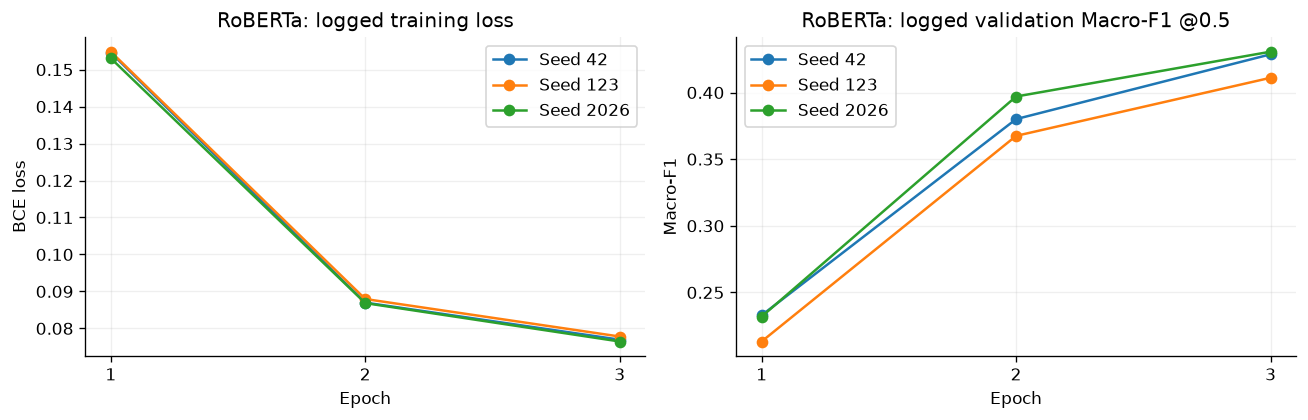

In [8]:
history = pd.DataFrame([{'seed':int(seed), **epoch} for seed,m in metadata.items() for epoch in m['history']])
display(history[['seed','epoch','train_loss','macro_f1','micro_f1','epoch_seconds']])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for seed, frame in history.groupby('seed'):
    axes[0].plot(frame.epoch, frame.train_loss, marker='o', label=f'Seed {seed}')
    axes[1].plot(frame.epoch, frame.macro_f1, marker='o', label=f'Seed {seed}')
axes[0].set(title='RoBERTa: logged training loss', xlabel='Epoch', ylabel='BCE loss')
axes[1].set(title='RoBERTa: logged validation Macro-F1 @0.5', xlabel='Epoch', ylabel='Macro-F1')
for ax in axes: ax.set_xticks([1,2,3]); ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

## 5. Từng seed và kiểm mean ± sample std

Macro-F1: tính F1 riêng mỗi nhãn rồi lấy trung bình đủ 28 nhãn.
Micro-F1: cộng TP/FP/FN trước khi tính. `ddof=1` là std mẫu qua ba seed.
Tuned-validation đã dùng chọn ngưỡng nên không là đánh giá độc lập.

In [9]:
c2 = runs[runs.system == 'C_roberta'].copy()
display(c2[c2.threshold_mode.isin(['fixed','tuned'])][
    ['seed','split','threshold_mode','macro_f1','micro_f1','micro_precision','micro_recall','hamming_loss']
].sort_values(['split','threshold_mode','seed']))

metrics = ['macro_f1','micro_f1','micro_precision','micro_recall','hamming_loss']
summary = c2.groupby(['split','threshold_mode'])[metrics].agg(['mean','std'])
display(summary)
for (split, mode), group in c2.groupby(['split','threshold_mode']):
    official = means.query("system == 'C_roberta' and split == @split and threshold_mode == @mode").iloc[0]
    assert len(group) == 3
    for metric in metrics:
        assert np.isclose(group[metric].mean(), official[metric + '_mean'], atol=1e-12, rtol=0)
        assert np.isclose(group[metric].std(ddof=1), official[metric + '_std'], atol=1e-12, rtol=0)
print('PASS: mean/std tính từ từng seed khớp hồ sơ gốc ở cả 6 tổ hợp split/ngưỡng.')

,seed,split,threshold_mode,macro_f1,micro_f1,micro_precision,micro_recall,hamming_loss
21,42.0,test,fixed,0.4213,0.5805,0.7077,0.4920,0.0296
27,123.0,test,fixed,0.4135,0.5794,0.7186,0.4854,0.0294
33,2026.0,test,fixed,0.4311,0.5811,0.7081,0.4928,0.0296
23,42.0,test,tuned,0.4835,0.6057,0.5516,0.6715,0.0364
29,123.0,test,tuned,0.4738,0.5988,0.5361,0.6781,0.0378
35,2026.0,test,tuned,0.5043,0.6101,0.5675,0.6595,0.0351
18,42.0,validation,fixed,0.4286,0.5780,0.7065,0.4890,0.0300
24,123.0,validation,fixed,0.4111,0.5730,0.7131,0.4788,0.0300
30,2026.0,validation,fixed,0.4306,0.5792,0.7058,0.4911,0.0300
20,42.0,validation,tuned,0.5008,0.6165,0.5681,0.6738,0.0352


macro_f1         micro_f1         micro_precision  \
                              mean     std     mean     std            mean   
split      threshold_mode                                                     
test       fixed            0.4219  0.0088   0.5803  0.0009          0.7115   
           global           0.4697  0.0092   0.5940  0.0158          0.5164   
           tuned            0.4872  0.0156   0.6048  0.0057          0.5517   
validation fixed            0.4234  0.0108   0.5767  0.0033          0.7085   
           global           0.4793  0.0084   0.5983  0.0135          0.5252   
           tuned            0.5072  0.0180   0.6144  0.0047          0.5658   

                                  micro_recall         hamming_loss  \
                              std         mean     std         mean   
split      threshold_mode                                             
test       fixed           0.0062       0.4901  0.0041       0.0295   
           global          0.0431       0.7041  0.0373       0.0402   
           tuned           0.0157       0.6697  0.0095       0.0365   
validation fixed           0.0040       0.4863  0.0066       0.0300   
           global          0.0433       0.7002  0.0411       0.0396   
           tuned           0.0148       0.6726  0.0103       0.0355   

                                       
                                  std  
split      threshold_mode              
test       fixed           1.4720e-04  
           global          4.7836e-03  
           tuned           1.3660e-03  
validation fixed           1.0054e-05  
           global          4.5633e-03  
           tuned           1.2174e-03

PASS: mean/std tính từ từng seed khớp hồ sơ gốc ở cả 6 tổ hợp split/ngưỡng.


## 6. Fixed vs tuned: tăng F1 đi kèm đánh đổi

Fixed: ngưỡng 0,5. Tuned: mỗi nhãn có ngưỡng chọn từ validation của đúng model/seed.
Test dùng ngưỡng đã khóa, không dùng test tìm ngưỡng lại. Hamming Loss càng thấp càng tốt.

,fixed,tuned,delta
macro_f1,0.4219,0.4872,0.0653
micro_f1,0.5803,0.6048,0.0245
micro_precision,0.7115,0.5517,-0.1597
micro_recall,0.4901,0.6697,0.1796
hamming_loss,0.0295,0.0365,0.0069


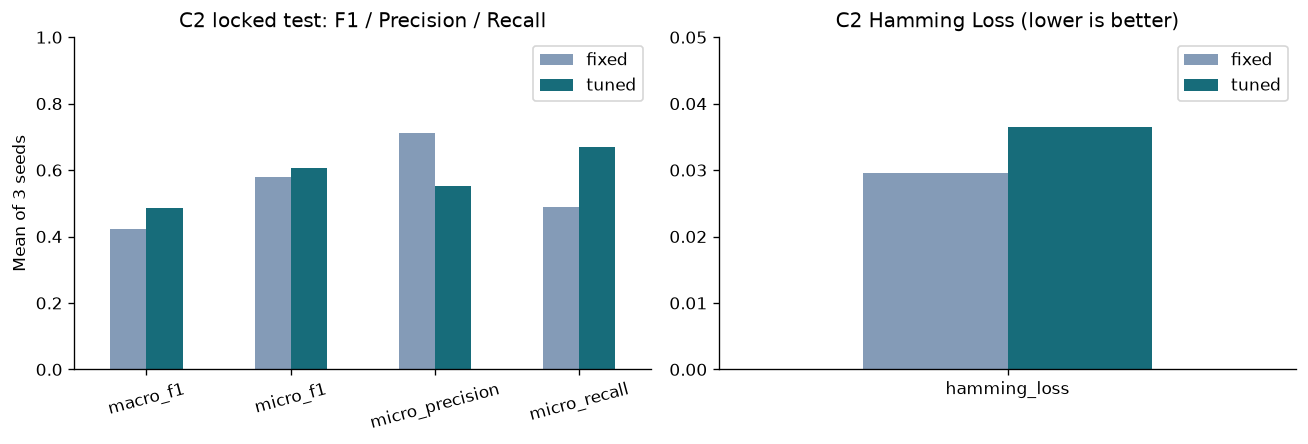

**Kết luận:** Macro-F1 tăng 0,4219 → 0,4872; Recall tăng, Precision giảm và Hamming Loss tăng. Không kết luận mọi chỉ số đều tốt hơn.

In [10]:
test_c2 = means.query("system == 'C_roberta' and split == 'test' and threshold_mode in ['fixed','tuned']").set_index('threshold_mode').loc[['fixed','tuned']]
keys = ['macro_f1','micro_f1','micro_precision','micro_recall','hamming_loss']
comparison = pd.DataFrame({mode: test_c2.loc[mode,[key+'_mean' for key in keys]].to_numpy(dtype=float) for mode in ['fixed','tuned']}, index=keys)
comparison['delta'] = comparison.tuned - comparison.fixed
display(comparison)
fig, axes = plt.subplots(1,2,figsize=(11,3.8))
comparison.loc[['macro_f1','micro_f1','micro_precision','micro_recall'],['fixed','tuned']].plot.bar(ax=axes[0],rot=15,color=['#849bb7','#176c7a'])
axes[0].set(title='C2 locked test: F1 / Precision / Recall',ylim=(0,1),ylabel='Mean of 3 seeds')
comparison.loc[['hamming_loss'],['fixed','tuned']].plot.bar(ax=axes[1],rot=0,color=['#849bb7','#176c7a'])
axes[1].set(title='C2 Hamming Loss (lower is better)',ylim=(0,.05))
plt.tight_layout();plt.show()
display(Markdown('**Kết luận:** Macro-F1 tăng 0,4219 → 0,4872; Recall tăng, Precision giảm và Hamming Loss tăng. Không kết luận mọi chỉ số đều tốt hơn.'))

## 7. So sánh ba C và tiêu chí chọn demo

Kiến trúc được chọn bằng mean Macro-F1 **validation @0,5**, đã chốt trước test.
Không đổi sang model khác chỉ vì thấy Micro-F1 test đẹp hơn. LR/epoch khác nhau giữa các C là giới hạn so sánh.

,system,macro_f1_mean,macro_f1_std
0,C_bert,0.4713,0.0066
6,C_roberta,0.4234,0.0108
12,C_distilbert,0.4064,0.0060


Kiến trúc thắng tiêu chí nhóm: C_bert


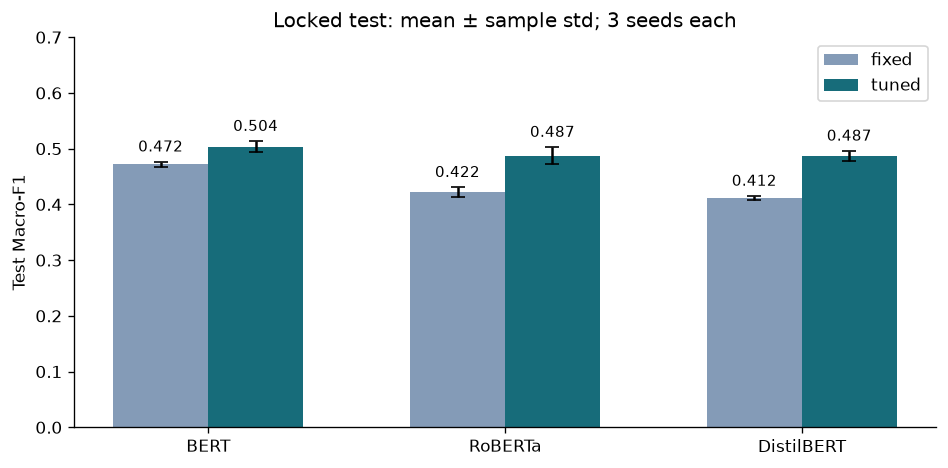

In [11]:
base = means.query("split == 'validation' and threshold_mode == 'fixed'")[['system','macro_f1_mean','macro_f1_std']].sort_values('macro_f1_mean',ascending=False)
display(base)
assert base.iloc[0].system == 'C_bert'
print('Kiến trúc thắng tiêu chí nhóm:', base.iloc[0].system)
fig,ax = plt.subplots(figsize=(8,4))
architectures = ['C_bert','C_roberta','C_distilbert']; x=np.arange(3)
for k,mode in enumerate(['fixed','tuned']):
    frame = means.query("split == 'test' and threshold_mode == @mode").set_index('system').loc[architectures]
    bars=ax.bar(x + (k-.5)*.32, frame.macro_f1_mean, width=.32,
        yerr=frame.macro_f1_std,capsize=4,label=mode,color=['#849bb7','#176c7a'][k])
    ax.bar_label(bars,fmt='%.3f',padding=4,fontsize=9)
ax.set(xticks=x,xticklabels=['BERT','RoBERTa','DistilBERT'],ylim=(0,.7),ylabel='Test Macro-F1',title='Locked test: mean ± sample std; 3 seeds each')
ax.legend();plt.tight_layout();plt.show()

## 8. Nhãn hiếm C2 — giữ cả nhãn không cải thiện

Danh sách hiếm xác định từ train, không dùng test để chọn nhãn.
F1 grief sau tuning vẫn bằng 0. Support test nhỏ và std lớn cần được nêu trong báo cáo.

,label,train_support,evaluation_support,before_f1_mean,before_f1_std,after_f1_mean,after_f1_std,delta_f1_mean
5,grief,77,6,0.0000,0.0000,0.0000,0.0000,0.0000
6,pride,111,16,0.0000,0.0000,0.1000,0.1732,0.1000
7,relief,153,11,0.0000,0.0000,0.0800,0.1386,0.0800
8,nervousness,164,23,0.0000,0.0000,0.3078,0.0443,0.3078
9,embarrassment,303,37,0.1222,0.1347,0.4461,0.0268,0.3238


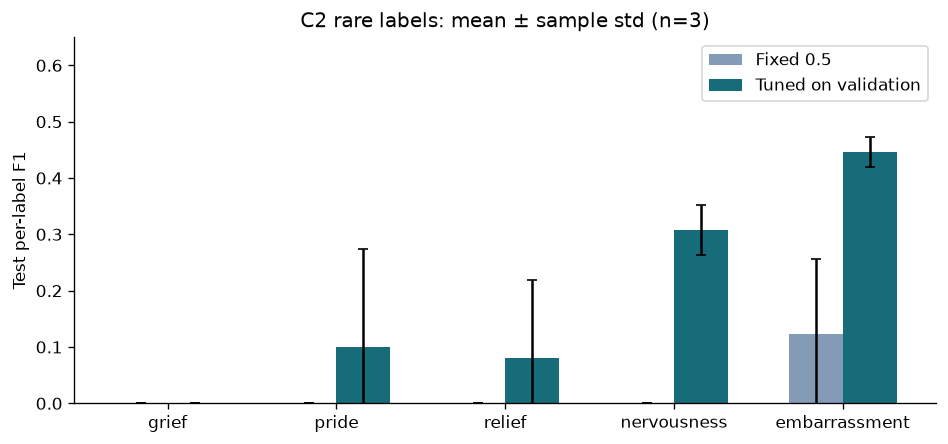

In [12]:
rare_test=rare.query("split == 'test'").copy()
display(rare_test[['label','train_support','evaluation_support','before_f1_mean','before_f1_std','after_f1_mean','after_f1_std','delta_f1_mean']])
fig,ax=plt.subplots(figsize=(8,3.8));x=np.arange(len(rare_test))
for k,(prefix,label) in enumerate([('before','Fixed 0.5'),('after','Tuned on validation')]):
    ax.bar(x+(k-.5)*.32,rare_test[prefix+'_f1_mean'],width=.32,
        yerr=rare_test[prefix+'_f1_std'],capsize=3,label=label,color=['#849bb7','#176c7a'][k])
ax.set(xticks=x,xticklabels=rare_test.label.tolist(),ylabel='Test per-label F1',ylim=(0,.65),title='C2 rare labels: mean ± sample std (n=3)')
ax.legend();plt.tight_layout();plt.show()

## 9. Ba ID có kết quả thật để đối chiếu lỗi

Các dòng sau chép từ `reports/error_case_studies.md` tại cùng commit. C2 dùng seed 2026 @0,5;
C1/C3 dùng seed đại diện chọn từ validation. Không chọn các seed bằng cách nhìn test.
Đây là ví dụ minh họa lỗi, không phải mọi dự đoán toàn test.

In [13]:
cases = pd.DataFrame([
    {'id':'eczj48j','true':'admiration, excitement, neutral','C2_pred':'admiration','C2_FN':'excitement, neutral','C2_FP':'không',
     'C2_scores':'admiration=0.6858; excitement=0.0218; neutral=0.0426','C1_pred':'caring','C3_pred':'admiration'},
    {'id':'ed0jr9i','true':'embarrassment','C2_pred':'không nhãn','C2_FN':'embarrassment','C2_FP':'không',
     'C2_scores':'embarrassment=0.3418','C1_pred':'embarrassment','C3_pred':'không nhãn'},
    {'id':'eczcvgx','true':'neutral','C2_pred':'neutral','C2_FN':'không','C2_FP':'không',
     'C2_scores':'neutral=0.6429','C1_pred':'neutral','C3_pred':'approval'}
])
display(cases)
print('TP: chọn đúng nhãn thật. FN: bỏ sót nhãn thật. FP: chọn nhãn không có trong ground truth.')
print('Case 1: C2 nhận một phần nhãn. Case 2: bỏ sót nhãn hiếm. Case 3: C2 đúng, C3 có FN neutral / FP approval.')

,id,true,C2_pred,C2_FN,C2_FP,C2_scores,C1_pred,C3_pred
0,eczj48j,"admiration, excitement, neutral",admiration,"excitement, neutral",không,admiration=0.6858; excitement=0.0218; neutral=...,caring,admiration
1,ed0jr9i,embarrassment,không nhãn,embarrassment,không,embarrassment=0.3418,embarrassment,không nhãn
2,eczcvgx,neutral,neutral,không,không,neutral=0.6429,neutral,approval


TP: chọn đúng nhãn thật. FN: bỏ sót nhãn thật. FP: chọn nhãn không có trong ground truth.
Case 1: C2 nhận một phần nhãn. Case 2: bỏ sót nhãn hiếm. Case 3: C2 đúng, C3 có FN neutral / FP approval.


## 10. Các ô để tự chạy C2 trong project của bạn

**Bản local cũ kiểm tra ngày 11/10 mới có EDA; nhánh notebook này kế thừa code C chung của main.** Cần nhận code mới của nhóm và checkpoint/scores lớn
nếu muốn dùng lại model; Git chỉ mang các tệp được theo dõi, không tự tạo weights.

Notebook điều khiển trainer chung để cùng loss/metrics/protocol với Khánh và Huy. Các ô Python bên dưới là code thực thi,
không phải hình chụp lệnh. Khi bật, log chạy được in ngay trong output ô notebook.

Thứ tự: kiểm môi trường → smoke → full 3 seed → đọc kết quả của chính bạn.
Nếu máy có GPU 4 GB và batch 16 thiếu VRAM, có thể chọn batch 4 / accumulation 4 để effective batch 16;
ghi cấu hình mới và giữ thống nhất ba seed. Không gộp run mới khác cấu hình với số benchmark nhúng.

Không tạo/cài lại môi trường đang chạy thí nghiệm. Xem `docs/CHAY_THUC_NGHIEM.md` và `requirements-models-lock.txt`
trong bản bàn giao để chọn PyTorch phù hợp máy. Chưa có packages thì chạy cài đặt trong đúng kernel trước.

In [14]:
# Đổi đường dẫn nếu bạn đặt repo mới ở chỗ khác.
PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p/'src/neural.py').is_file()), Path(r'D:\NLP\Do_An_NhanDienCamXuc'))
RUN_SMOKE = False       # True: pilot 64 train / 32 validation, 1 epoch; không dùng báo cáo benchmark.
RUN_FULL = False        # True: train lại RoBERTa đủ 3 seed; có thể tốn hàng giờ.
READ_LOCAL_RUNS = False # True: kiểm model/scores trên máy của bạn, không dùng snapshot GitHub.
RUN_LOCKED_TEST = False # True: đánh giá sau khi nhóm đã khóa final_protocol.json.
DEVICE = 'auto'
BATCH_SIZE = 16
GRADIENT_ACCUMULATION = 1

required_files=['scripts/train_transformer.py','src/neural.py','src/metrics.py','data/labels.json']
repo_checks = pd.DataFrame({'file':required_files,'exists':[(PROJECT_ROOT/name).is_file() for name in required_files]})
display(repo_checks)
print('Packages trong kernel:',{name:importlib.util.find_spec(name) is not None for name in ['torch','transformers','numpy','pandas','pyarrow','sklearn']})
print('Training flags:',RUN_SMOKE,RUN_FULL,'; local results flag:',READ_LOCAL_RUNS)

,file,exists
0,scripts/train_transformer.py,True
1,src/neural.py,True
2,src/metrics.py,True
3,data/labels.json,True


Packages trong kernel: {'torch': True, 'transformers': False, 'numpy': True, 'pandas': True, 'pyarrow': True, 'sklearn': True}
Training flags: False False ; local results flag: False


### 10.1. Hiểu tokenizer và tensor đầu vào bằng checkpoint thật

Tokenizer RoBERTa chia subword theo checkpoint; token count khác word count.
`input_ids`: mã token; `attention_mask`: 1 cho token thật, 0 cho padding.
`RUN_TOKENIZER` chỉ tải tokenizer khi bạn bật; mặc định không có token output giả.

In [15]:
RUN_TOKENIZER=False
TOKENIZER_REVISION='e2da8e2f811d1448a5b465c236feacd80ffbac7b'
if RUN_TOKENIZER:
    from transformers import AutoTokenizer
    tokenizer=AutoTokenizer.from_pretrained('FacebookAI/roberta-base',revision=TOKENIZER_REVISION)
    texts=[sample['text'] for sample in TRAIN_EXAMPLES[:2]]
    encoded=tokenizer(texts,truncation=True,padding=True,max_length=128,return_tensors='pt')
    print('input_ids shape:',tuple(encoded['input_ids'].shape))
    print('attention_mask:',encoded['attention_mask'])
    for text,ids,mask in zip(texts,encoded['input_ids'],encoded['attention_mask']):
        tokens=tokenizer.convert_ids_to_tokens(ids.tolist())
        display(pd.DataFrame({'token':tokens,'input_id':ids.tolist(),'attention':mask.tolist()}))
else:
    print('Tokenizer model thật chưa chạy: đặt RUN_TOKENIZER=True sau khi cài transformers và có mạng/cache.')

Tokenizer model thật chưa chạy: đặt RUN_TOKENIZER=True sau khi cài transformers và có mạng/cache.


### 10.2. Xem một forward pass và loss của RoBERTa thật

Warning head mới khởi tạo là bình thường: checkpoint ngôn ngữ chưa có head 28 nhãn của đồ án.
Ô này chỉ kiểm tensor/forward, **không phải mô hình fine-tune hoàn tất** và không tạo số F1.
Chỉ bật sau tokenizer. Giải phóng model sau demo để không chiếm VRAM khi train.

In [16]:
RUN_FORWARD=False
if RUN_FORWARD:
    if not RUN_TOKENIZER:
        raise RuntimeError('Bật/chạy ô tokenizer trước.')
    import gc, torch
    from transformers import AutoModelForSequenceClassification
    target=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    fresh_model=AutoModelForSequenceClassification.from_pretrained(
        'FacebookAI/roberta-base',revision=TOKENIZER_REVISION,num_labels=28,
        problem_type='multi_label_classification',
        id2label=dict(enumerate(label_names)),label2id={name:i for i,name in enumerate(label_names)})
    fresh_model.to(target).eval()
    batch={k:v.to(target) for k,v in encoded.items()}
    true_tensor=torch.tensor(explain_multi_hot([r['label_ids'] for r in TRAIN_EXAMPLES[:2]]),device=target)
    with torch.no_grad():
        forward_logits=fresh_model(**batch).logits
        forward_loss=torch.nn.BCEWithLogitsLoss()(forward_logits,true_tensor)
    print('Model logits:',tuple(forward_logits.shape),'labels:',tuple(true_tensor.shape),'loss:',float(forward_loss))
    assert forward_logits.shape==true_tensor.shape==(2,28)
    del fresh_model,batch,true_tensor,forward_logits,forward_loss
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
else:
    print('Forward model chưa chạy; chỉ bật để kiểm luồng, không dùng scores head chưa học làm benchmark.')

Forward model chưa chạy; chỉ bật để kiểm luồng, không dùng scores head chưa học làm benchmark.


### 10.3. Bên trong vòng lặp fine-tune của nhóm

Notebook dùng trainer chung để giữ artifact/metrics/protocol đồng nhất. Các dòng cốt lõi:

```python
model.train()                              # Bật chế độ huấn luyện
logits = model(**inputs).logits            # N×28, chưa sigmoid
loss = multilabel_loss(logits, targets)    # BCE, targets float
loss.backward()                           # Tính gradient
optimizer.step()                          # Cập nhật encoder và head
optimizer.zero_grad()                     # Xóa gradient cho bước tiếp
```

Trainer thật còn có AMP/GradScaler, clipping, scheduler và gradient accumulation;
đừng thay nguyên vòng lặp thật bằng snippet trên. Khi validation dùng `eval()` và `no_grad()`.
`src/neural.py` đặt seed, cấu hình; `scripts/train_transformer.py` thực hiện train và lưu checkpoint.
Các hàm thật sau được in để bạn đọc tại chỗ, không tải hoặc train model.

In [17]:
if all((PROJECT_ROOT/name).is_file() for name in required_files):
    sys.path.insert(0,str(PROJECT_ROOT))
    import inspect
    from IPython.display import Code
    from src.neural import multilabel_loss, training_config
    from scripts.train_transformer import encoded_dataset,trim_padding_collate,predict_scores
    display(Code(inspect.getsource(multilabel_loss),language='python'))
    display(Code(inspect.getsource(encoded_dataset),language='python'))
    display(Code(inspect.getsource(predict_scores),language='python'))
else:
    print('Nhận repo mới để đọc các hàm trainer thật trong output ô này.')

def multilabel_loss(logits, targets, pos_weight=None):
    """Logits N×28 + nhãn float N×28 -> BCE; chưa sigmoid ở bước loss."""
    import torch
    if logits.ndim != 2 or logits.shape != targets.shape or not targets.is_floating_point():
        raise ValueError("logits và nhãn float phải cùng shape N × L")
    return torch.nn.functional.binary_cross_entropy_with_logits(
        logits, targets, pos_weight=pos_weight
    )

def encoded_dataset(frame, tokenizer, labels, max_length):
    """Tokenize một lần trước epochs; nhãn float để BCE hỗ trợ đa nhãn."""
    import torch
    tokenizer.padding_side = "right"  # Collate bên dưới chỉ loại padding ở cuối câu.
    tokens = tokenizer(frame["text"].tolist(), truncation=True, padding="max_length",
                       max_length=max_length, return_tensors="pt")
    targets = torch.tensor(multi_hot(frame["labels"].tolist(), len(labels)), dtype=torch.float32)

    class TextDataset(torch.utils.data.Dataset):
        def __len__(self):
            return len(targets)

        def __getitem__(self, index):
            return {**{name: values[index] for name, values in tokens.items()},
                    "labels": targets[index]}

    return TextDataset(), targets.numpy()

def predict_scores(model, loader, device):
    """model.eval + no_grad; sigmoid độc lập cho 28 cảm xúc, không softmax."""
    import torch
    model.eval()
    batches = []
    with torch.no_grad():
        for batch in loader:
            inputs = {name: value.to(device) for name, value in batch.items() if name != "labels"}
            context = torch.autocast("cuda", dtype=torch.float16) if device.type == "cuda" else nullcontext()
            with context:
                logits = model(**inputs).logits
            if logits.ndim != 2 or logits.shape[1] != 28:
                raise ValueError("Head Transformer phải trả N × 28 logits")
            batches.append(torch.sigmoid(logits.float()).cpu().numpy())
    return np.concatenate(batches)

### 10a. Hàm chạy trainer và giữ log trong output

Chỉ chạy trong repo cập nhật có đủ modules. Dùng chính `sys.executable` của kernel để không trộn Python khác.
`--resume` bỏ qua run đã hoàn tất hợp lệ, không resume optimizer ở giữa epoch. Không tự bật `--overwrite`.

In [18]:
def run_group_script(module, arguments):
    missing=[name for name in required_files if not (PROJECT_ROOT/name).is_file()]
    if missing:
        raise RuntimeError('Project đang thiếu code mới: '+', '.join(missing))
    command=[sys.executable,'-u','-m',module,*map(str,arguments)]
    print('Chạy:',subprocess.list2cmdline(command),flush=True)
    env=os.environ.copy();env['PYTHONUTF8']='1';env['PYTHONUNBUFFERED']='1'
    process=subprocess.Popen(command,cwd=str(PROJECT_ROOT),env=env,stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,text=True,encoding='utf-8',errors='replace')
    try:
        for line in process.stdout:
            print(line,end='',flush=True)
        return_code=process.wait()
    except KeyboardInterrupt:
        process.terminate();process.wait()
        raise
    if return_code:
        raise RuntimeError(f'{module} kết thúc với mã lỗi {return_code}; kiểm output phía trên.')

if RUN_SMOKE:
    run_group_script('scripts.train_transformer',[
        '--architecture','roberta','--seed',42,'--smoke','--device',DEVICE,
        '--batch-size',BATCH_SIZE,'--gradient-accumulation',GRADIENT_ACCUMULATION,'--resume'])
else:
    print('Smoke chưa chạy: đổi RUN_SMOKE=True khi đã có đúng repo và môi trường.')

Smoke chưa chạy: đổi RUN_SMOKE=True khi đã có đúng repo và môi trường.


### 10b. Chạy full đủ 3 seed C2

Đầu ra nằm trong `data/processed/transformers/roberta/seed_<seed>/full/standard/`:
checkpoint, validation_scores.npz, validation_metrics.json, run_metadata.json.
Trainer thật cập nhật toàn bộ encoder/head bằng BCE; chọn checkpoint bằng validation Macro-F1 @0,5.

In [19]:
if RUN_FULL:
    for seed in [42,123,2026]:
        run_group_script('scripts.train_transformer',[
            '--architecture','roberta','--seed',seed,'--device',DEVICE,
            '--batch-size',BATCH_SIZE,'--gradient-accumulation',GRADIENT_ACCUMULATION,
            '--max-length',128,'--learning-rate',2e-5,'--epochs',3,
            '--revision','e2da8e2f811d1448a5b465c236feacd80ffbac7b','--resume'])
else:
    print('FULL chưa chạy trong notebook này. Các biểu đồ phía trên đọc hồ sơ full của nhóm.')

FULL chưa chạy trong notebook này. Các biểu đồ phía trên đọc hồ sơ full của nhóm.


### 10c. Đọc model artifacts mới và tự chấm validation bằng metrics chung

`load_transformer_run` kiểm completed/full, mapping, revision và SHA-256 của checkpoint/scores.
Ghép scores theo ID vào dữ liệu; không dựa vào việc CSV tình cờ có cùng thứ tự.
Kết quả ô này khi bật là từ artifacts trên máy bạn; không fallback sang snapshot nếu thiếu.

In [20]:
if READ_LOCAL_RUNS:
    sys.path.insert(0,str(PROJECT_ROOT))
    from src.neural import load_transformer_run
    from src.data import load_goemotions, multi_hot
    from src.metrics import evaluate_multilabel
    from src.baseline import load_aligned_scores
    frames, names, _ = load_goemotions(PROJECT_ROOT,write_metadata=False,splits=('validation',))
    frame=frames['validation']; truth=multi_hot(frame.labels.tolist(),len(names))
    local_rows=[]
    for seed in [42,123,2026]:
        folder=PROJECT_ROOT/f'data/processed/transformers/roberta/seed_{seed}/full/standard'
        m=load_transformer_run(folder,require_full=True)
        scores=load_aligned_scores(folder/'validation_scores.npz',frame.id,names)
        result=evaluate_multilabel(truth,scores,names,threshold=.5)
        local_rows.append({'seed':seed,**{key:result[key] for key in metrics}})
    local_results=pd.DataFrame(local_rows).set_index('seed')
    display(local_results)
    display(local_results.agg(['mean','std']))
    print('Đây là metrics tự tính từ local scores; không sử dụng benchmark nhúng.')
else:
    print('Chưa đọc/chấm local scores. Đổi READ_LOCAL_RUNS=True sau khi có đủ artifacts full.')

Chưa đọc/chấm local scores. Đổi READ_LOCAL_RUNS=True sau khi có đủ artifacts full.


### 10c-bổ sung. Chọn ngưỡng trên validation và khóa protocol

28 nhãn có phân bố/score khác nhau; chọn riêng trên validation của đúng checkpoint/seed.
Trainer của nhóm dùng lưới 0,05..0,95, bước 0,05; khi F1 hòa ưu tiên ngưỡng gần 0,5,
nếu vẫn hòa chọn ngưỡng lớn hơn. Tuning không train lại encoder/head.

`final_protocol.json` lưu ngưỡng, mapping, revision và hash metadata/scores. **Không ghi đè** nếu đã có protocol.
Trước lần chạy test đầu tiên, cả nhóm cần khóa lựa chọn; test đã mở thì giữ protocol.

In [21]:
FREEZE_VALIDATION=False
if FREEZE_VALIDATION:
    for seed in [42,123,2026]:
        folder=PROJECT_ROOT/f'data/processed/transformers/roberta/seed_{seed}/full/standard'
        if (folder/'final_protocol.json').exists():
            print(f'Seed {seed}: protocol đã có; giữ nguyên, không chọn lại ngưỡng.')
        else:
            run_group_script('scripts.freeze_experiment',['--run-dir',folder,'--threshold-mode','tuned'])
else:
    print('Chưa khóa protocol mới. Snapshot phía trên đã được nhóm khóa/đánh giá trước đó.')

Chưa khóa protocol mới. Snapshot phía trên đã được nhóm khóa/đánh giá trước đó.


### 10d. Test sau khóa protocol

Chỉ bật khi từng run có `final_protocol.json` đã chốt từ validation theo quy trình nhóm.
Không dùng những câu test đã đọc để chọn lại model/seed/ngưỡng. Ô này kiểm protocol và
suy luận bằng checkpoint của đúng run; không tự tạo ngưỡng mới từ test.

In [22]:
if RUN_LOCKED_TEST:
    folders=[PROJECT_ROOT/f'data/processed/transformers/roberta/seed_{seed}/full/standard' for seed in [42,123,2026]]
    if not all((folder/'final_protocol.json').is_file() for folder in folders):
        raise RuntimeError('Thiếu protocol đã khóa. Dừng test và phối hợp nhóm khóa lựa chọn bằng validation trước.')
    for folder in folders:
        run_group_script('scripts.evaluate_transformer_test',[
            '--run-dir',str(folder),'--protocol',str(folder/'final_protocol.json'),'--device',DEVICE])
else:
    print('Không đánh giá lại test trong phiên này; dùng kết quả locked đã có để đọc báo cáo.')

Không đánh giá lại test trong phiên này; dùng kết quả locked đã có để đọc báo cáo.


### 10e. Phân tích lỗi validation từ scores thật trên máy bạn

Chỉ bật sau khi có scores validation và data cache. Ghép bằng ID, dùng threshold 0,5 ở ô này.
In nhãn thật, dự đoán, FN/FP và nguyên văn; heatmap đếm FN nhãn hàng + FP nhãn cột cùng câu.
Đây là lỗi dự đoán, khác ma trận đồng xuất hiện nhãn thật. Không cộng số cặp thành số câu sai.

In [23]:
ANALYZE_LOCAL_ERRORS=False
if ANALYZE_LOCAL_ERRORS:
    sys.path.insert(0,str(PROJECT_ROOT))
    from src.data import load_goemotions,multi_hot
    from src.baseline import load_aligned_scores,label_error_pairs
    from src.neural import load_transformer_run
    frames,names,_=load_goemotions(PROJECT_ROOT,write_metadata=False,splits=('validation',))
    frame=frames['validation']; seed=2026
    folder=PROJECT_ROOT/f'data/processed/transformers/roberta/seed_{seed}/full/standard'
    load_transformer_run(folder,require_full=True)
    scores=load_aligned_scores(folder/'validation_scores.npz',frame.id,names)
    truth=multi_hot(frame.labels.tolist(),28).astype(bool);pred=scores>=.5
    missed=truth & ~pred;extra=~truth & pred
    records=[]
    for row_index in np.flatnonzero(np.any(missed|extra,axis=1))[:10]:
        r=frame.iloc[int(row_index)]
        decode=lambda row:', '.join(np.array(names)[np.asarray(row,dtype=bool)]) or 'không nhãn'
        records.append({'id':r.id,'text':r.text,'true':decode(truth[row_index]),
            'pred':decode(pred[row_index]),'FN':decode(missed[row_index]),'FP':decode(extra[row_index])})
    display(pd.DataFrame(records))
    display(pd.DataFrame(label_error_pairs(truth,scores,names,.5)).head(10))
    matrix=missed.astype(np.int64).T @ extra.astype(np.int64)
    fig,ax=plt.subplots(figsize=(10,8));im=ax.imshow(matrix,cmap='YlOrRd')
    ax.set_xticks(range(28),names,rotation=90);ax.set_yticks(range(28),names)
    ax.set(xlabel='Extra predicted label (FP)',ylabel='Missed true label (FN)',title='C2 validation FN/FP pairs')
    fig.colorbar(im,ax=ax);plt.tight_layout();plt.show()
else:
    print('Chưa phân tích local scores; ba case đã lưu phía trên có nguồn hồ sơ nhóm.')

Chưa phân tích local scores; ba case đã lưu phía trên có nguồn hồ sơ nhóm.


### 10f. Dự đoán câu mới bằng checkpoint đã fine-tune

Chỉ dùng checkpoint `full/standard` đã kiểm hash; không dùng head mới khởi tạo ở ô forward.
Ô này dùng ngưỡng cố định 0,5. Muốn dùng tuned phải đọc protocol đúng seed, không lấy ngưỡng mô hình khác.
Văn bản tiếng Anh; scores chưa được hiệu chuẩn xác suất. Nếu không có nhãn vượt ngưỡng, không tự gán neutral.

In [24]:
RUN_INFERENCE=False
if RUN_INFERENCE:
    import torch,gc
    from transformers import AutoTokenizer,AutoModelForSequenceClassification
    sys.path.insert(0,str(PROJECT_ROOT))
    from src.neural import load_transformer_run
    folder=PROJECT_ROOT/'data/processed/transformers/roberta/seed_2026/full/standard'
    m=load_transformer_run(folder,require_full=True)
    tokenizer=AutoTokenizer.from_pretrained(folder/'checkpoint',local_files_only=True)
    trained_model=AutoModelForSequenceClassification.from_pretrained(folder/'checkpoint',local_files_only=True).eval()
    text='Thank you so much! I am happy you could help.'
    inputs=tokenizer(text,truncation=True,max_length=m['config']['max_length'],return_tensors='pt')
    with torch.no_grad():
        probabilities=torch.sigmoid(trained_model(**inputs).logits.float())[0].numpy()
    output=pd.DataFrame({'label':m['label_names'],'score':probabilities,'threshold':.5})
    output['selected']=output.score>=output.threshold
    display(output.sort_values('score',ascending=False))
    print('Nhãn chọn:',output.loc[output.selected,'label'].tolist())
    del trained_model;gc.collect()
else:
    print('Suy luận câu mới chưa chạy; notebook không gán sẵn joy/gratitude cho câu ví dụ.')

Suy luận câu mới chưa chạy; notebook không gán sẵn joy/gratitude cho câu ví dụ.


## 11. Checklist báo cáo cá nhân

- [ ] Giải thích text → tokenizer → encoder → 28 logits; BCE, sigmoid và multi-hot.
- [ ] Giải thích seed, epoch được chọn và thông số C2 là cấu hình nhóm.
- [ ] Trình bày từng seed, mean/std, validation/test; không chỉ seed đẹp nhất.
- [ ] Trình bày tuning tăng Macro-F1 nhưng giảm Precision, tăng Hamming; grief vẫn chưa cải thiện.
- [ ] Phân tích 2–3 ID thật, đối chiếu cùng ID với Khánh/Huy.
- [ ] Xác nhận việc cá nhân đã làm và nơi lưu checkpoint/scores; không tự nhận đã chạy nếu mới đọc hồ sơ.
- [ ] Viết phần C2: phương pháp, cấu hình, kết quả, lỗi, hạn chế; đưa notebook này và artifacts thật cho nhóm.

**Bạn cần làm C2; không phải viết lại baseline A, BERT C1, DistilBERT C3 hoặc demo D.**
Notebook là nơi trình bày code/output; dùng trainer/metrics chung giúp kết quả ghép được với cả nhóm.

In [25]:
display(Markdown('### Nguồn snapshot và code'))
for name,url in SNAPSHOT['sources'].items():
    display(Markdown(f'- [{name}]({url})'))
print('Phân công: nội dung Notion 10/10 người dùng cung cấp và docs/KE_HOACH_NHOM.md.')
print('Phạm vi đã chạy: đọc snapshot, bảng/biểu đồ/mean/std và ví dụ toán học. Training/suy luận C2 mới: CHƯA CHẠY.')

### Nguồn snapshot và code

- [reports/project_results/all_runs.csv](https://github.com/trangkhanh-ai/goemotions-multilabel-classification/blob/3c44309ec287d3a2926acdd67a9b6a18da11a4d2/reports/project_results/all_runs.csv)

- [reports/project_results/mean_std.csv](https://github.com/trangkhanh-ai/goemotions-multilabel-classification/blob/3c44309ec287d3a2926acdd67a9b6a18da11a4d2/reports/project_results/mean_std.csv)

- [reports/project_results/rare_before_after.csv](https://github.com/trangkhanh-ai/goemotions-multilabel-classification/blob/3c44309ec287d3a2926acdd67a9b6a18da11a4d2/reports/project_results/rare_before_after.csv)

- [reports/error_case_studies.md](https://github.com/trangkhanh-ai/goemotions-multilabel-classification/blob/3c44309ec287d3a2926acdd67a9b6a18da11a4d2/reports/error_case_studies.md)

- [scripts/train_transformer.py](https://github.com/trangkhanh-ai/goemotions-multilabel-classification/blob/3c44309ec287d3a2926acdd67a9b6a18da11a4d2/scripts/train_transformer.py)

- [src/neural.py](https://github.com/trangkhanh-ai/goemotions-multilabel-classification/blob/3c44309ec287d3a2926acdd67a9b6a18da11a4d2/src/neural.py)

Phân công: nội dung Notion 10/10 người dùng cung cấp và docs/KE_HOACH_NHOM.md.
Phạm vi đã chạy: đọc snapshot, bảng/biểu đồ/mean/std và ví dụ toán học. Training/suy luận C2 mới: CHƯA CHẠY.
